In [1]:
import numpy as np
import pandas as pd
import csv
from scipy.constants import mu_0, epsilon_0
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import ipywidgets
import discretize
import  os
import json
from PIL import Image
import seaborn as sns
import pandas as pd
from matplotlib.backends.backend_pdf import PdfPages
import ipywidgets as widgets
eps = np.finfo(float).eps

In [2]:
import empymod
from scipy.special import logsumexp

from masa_utils import PsuedoLog, Optimization
from masa_utils import empymod_IP_simulation,TEM_Signal_Process
from masa_utils import multiple_dataset_simulation

Simulatin and synthetic study on deep sea hydrothermal deposits explortaion using WISTEM (K. Nakayama and A. Saito, 2016) (K.Nakayama M. Motoori and A. Saito,2019). On-Time: 200msec ramp time: 200usec Transmitter Loop: 3.5m Square Loop Receiver Loop: Coincident-type Number of Turn: 5 3.5m rectangular loop has equivalent area for 2.0m circular loop.

In [3]:
plt.style.use('00_figures.mplstyle')
textwidth = 5.60739


In [4]:
# --- helper to render LaTeX labels (robust method) ---
def math_label(tex, width="160px"):
    out = widgets.Output(layout=widgets.Layout(width=width))
    with out:
        display(Math(tex))
    return out
def sci_latex(v, prec=2):
    s = f"{v:.{prec}e}"          # e.g. '3.00e-03'
    mant, exp = s.split('e')
    exp = int(exp)

    if float(mant) == 0:
        return "0"

    if exp in [0, -1]:
        return f"{float(mant)*10**exp:.{prec}f}"
    else:
        return rf"{mant}\cdot 10^{{{exp}}}"


def fmt(v, prec=2, latex=False, wrap=False):
    # blank for None or empty string
    if v is None or v == "":
        return ""

    # if already string → return as-is
    if isinstance(v, str):
        return v

    try:
        s = sci_latex(v, prec=prec)

        if latex:
            if wrap:
                return rf"$${s}$$"   # display math
            else:
                return rf"${s}$"     # inline math
        else:
            return s

    except:
        return ""


In [5]:

rmp_time=200e-6

smp_freq=50e3 #200e3  

In [6]:
tx_side = 3.5
tx_radius = (tx_side)/(np.sqrt(np.pi))
tx_circumeference = 2*np.pi*tx_radius
tx_surface = np.pi*tx_radius**2
n_turns = 5
tx_depth = 0
print(f"Transmitter radius: {tx_radius}")

Transmitter radius: 1.9746635424171473


In [7]:
tstrt, tend = 1e-4, 1e-2
logstep = 1/15
WISTEM_SP_sim = TEM_Signal_Process(
    rmp_time=rmp_time, 
    rec_time=tend, 
    smp_freq=smp_freq
)


In [8]:
times_sim = WISTEM_SP_sim.times_rec
times_clc = WISTEM_SP_sim.times_rec
ntimes = len(times_clc)
print(ntimes)
print(times_clc[:3], times_clc[-3:])
WISTEM_SP_sim.get_window_log(tstart=tstrt,logstep=logstep)
windows_strt = WISTEM_SP_sim.windows_strt
windows_cen = WISTEM_SP_sim.windows_cen
windows_end = WISTEM_SP_sim.windows_end
print(windows_cen-rmp_time)
nD = len(windows_cen)

500
[2.e-05 4.e-05 6.e-05] [0.00996 0.00998 0.01   ]
[0.0001     0.00011651 0.00013575 0.00015817 0.00018429 0.00021472
 0.00025018 0.00029149 0.00033962 0.0003957  0.00046104 0.00053718
 0.00062588 0.00072923 0.00084965 0.00098995 0.00115342 0.00134388
 0.0015658  0.00182436 0.00212561 0.00247661 0.00288558 0.00336207
 0.00391725 0.0045641  0.00531777 0.00619589 0.00721901 0.00841108]


In [9]:
nlayer = 11
eta_sea , eta_base = 0.,0.
tau_sea, tau_base = 1e-3, 1e-3
c_sea, c_base = 0.5,.5
thick_layer = 2.0
res_sea, res_target, res_base = 0.3, 0.1,10
eta_sea, eta_target, eta_base = 0, 0.4, 0.0
tau_sea, tau_target, tau_base = 1e-3, 1e-3, 1e-3
c_sea, c_target, c_base = 0.5, 0.7, 0.5
depth = thick_layer*np.arange(nlayer-1)
tx_height = 4.0

depth+=tx_height
print(f"depth {depth}")

depth [ 4.  6.  8. 10. 12. 14. 16. 18. 20. 22.]


In [10]:
nmodel=5 #4
# res_ref_list = [10,3,1.0,0.3]

nlayer_target_list = [1,2,3,4,5]
m_trues= []
thickness_list = []
for nlayer_target in nlayer_target_list:
    nlayer_bottom = nlayer-nlayer_target-1
    m_true = np.r_[np.log(res_target)*np.ones(nlayer_target),
                   np.log(res_base)*np.ones(nlayer_bottom),
                   eta_target*np.ones(nlayer_target),
                   eta_base*np.ones(nlayer_bottom),
                   np.log(tau_target)*np.ones(nlayer_target),
                   np.log(tau_base)*np.ones(nlayer_bottom),
                   c_target*np.ones(nlayer_target),
                   c_base*np.ones(nlayer_bottom)]
    m_trues.append(m_true)
    thickness_list.append(thick_layer*nlayer_target)



In [11]:

m_refs = []

for i in range(nmodel):
    m_ref = np.r_[np.log(res_sea)*np.ones(nlayer-1),
                 eta_sea*np.ones(nlayer-1),
                 np.log(tau_sea)*np.ones(nlayer-1),
                 c_sea*np.ones(nlayer-1)]
    m_refs.append(m_ref)



In [12]:
WISTEM_SP_sim.get_window_log(tstart=tstrt,logstep=logstep)
filt_linrmp = WISTEM_SP_sim.filter_linear_rmp()

Window_mat = WISTEM_SP_sim.get_window_matrix(times_sim)
print(Window_mat.shape)

(30, 500)


In [13]:
recx, recy = 0 , 0
recBdple = [recx, recy, tx_depth ,0,90]
# recx, recy, recw = rec_area(3, tx_side)
# recBdple = [recx, recy, tx_depth ,0,90]

In [14]:
# emoymod model to simulate WISTEM setting
# Note that it simulate only dBdt field at center of the transmitter loop
# User should multiply by area of the loop to get EMF(V/A)
empymod_model_sim = {
    # simulate each bipole of four side of the transmitter loop
    'src': [ tx_side/2, tx_side/2,  # x1,x2
                     0, tx_side/2,  # y1,y2
             tx_depth, tx_depth], # z1,z2
    # receiver at the center of the transmitter loop
    'rec': recBdple, # [recx, recy, tx_depth ,0,90], # dBzdt at x,y,z,azimuth,dip
    'depth': depth,
#    'res' : res,
#    'freqtime': times_sim,
    'signal': None, # 0: impulse or dBdt, 1: Stepoff or B field
    'msrc' : False, # Electric source
    'mrec' : True, # Magnetic receiver
    'strength': 8.*n_turns* tx_surface * mu_0,  
    'srcpts' : 3,  # Three works for the momtent, maybe worth seeking other number
    'verb': 0, # put 4 for more information
     # Setting xdirect=True can help, as direct field is then computed analytically in f-domain
    'xdirect': True,
}

In [15]:
sim_obs=empymod_IP_simulation(ip_model='pelton',
    model_base=empymod_model_sim, nlayer=nlayer,tx_height=tx_height,
    times=times_sim, smp_freq=smp_freq,nD=nD
    )
sim_obs.deepsea_fix_sea(
    res_sea=res_sea, eta_sea=eta_sea, 
    tau_sea=tau_sea, c_sea=c_sea, 
    )


In [16]:
print(sim_obs.m_fix)
print(sim_obs.model_base)

[-1.2039728   0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.         -6.90775528  0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.5         0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.        ]
{'src': [1.75, 1.75, 0, 1.75, 0, 0], 'rec': [0, 0, 0, 0, 90], 'depth': array([ 4.,  6.,  8., 10., 12., 14., 16., 18., 20., 22.]), 'signal': None, 'msrc': False, 'mrec': True, 'strength': np.float64(0.0006157521600223001), 'srcpts': 3, 'verb': 0, 'xdirect': True}


In [17]:
mvec_obs = m_true
sim_obs.cut_off = None
dpred_step= sim_obs.dpred(mvec_obs)
sim_obs.cut_off = smp_freq/2.0
print(f"cutoff frequency: {sim_obs.cut_off}")
dpred_LPF = sim_obs.dpred(mvec_obs)
sim_obs.filt_curr = filt_linrmp
dpred_rmp = sim_obs.dpred(mvec_obs)
sim_obs.window_mat=Window_mat
dpred_window = sim_obs.dpred(mvec_obs)

cutoff frequency: 25000.0


In [18]:
PL_decay = PsuedoLog(
    logmin=1e-8,
    linScale=0.5,
    logminx=1e-4,
    linScalex=0.5
    )
PL_jac = PsuedoLog(
    logmin=1.0,
    linScale=1.0,
    logminx=1e-4,
    linScalex=0.2
    )


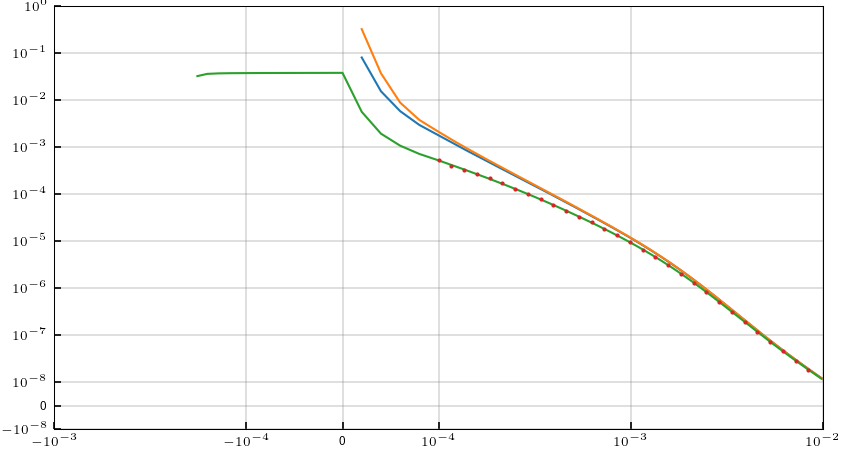

In [19]:
fig, ax= plt.subplots(1,1, figsize=(textwidth,3))

ax= PL_decay.plpl_plot(
     x=times_clc,y=dpred_step , linestyle="-",label="obs", color="C0",ax=ax)
ax= PL_decay.plpl_plot(
     x=times_clc,y=dpred_LPF , linestyle="-",label="Low Pass filtered", color="C1",ax=ax)
ax= PL_decay.plpl_plot(
     x=times_clc-rmp_time,y=dpred_rmp , linestyle="-",label="wvf", color="C2",ax=ax)
ax= PL_decay.plpl_plot(
     x= windows_cen-rmp_time,y=dpred_window , marker="o",linestyle="",label="windowed", color="C3",ax=ax)
ax= PL_decay.pl_axes(ax)
ax= PL_decay.pl_axes_x(ax)


In [20]:
relative_error=0.05
data_noise_floor = 0.1e-7



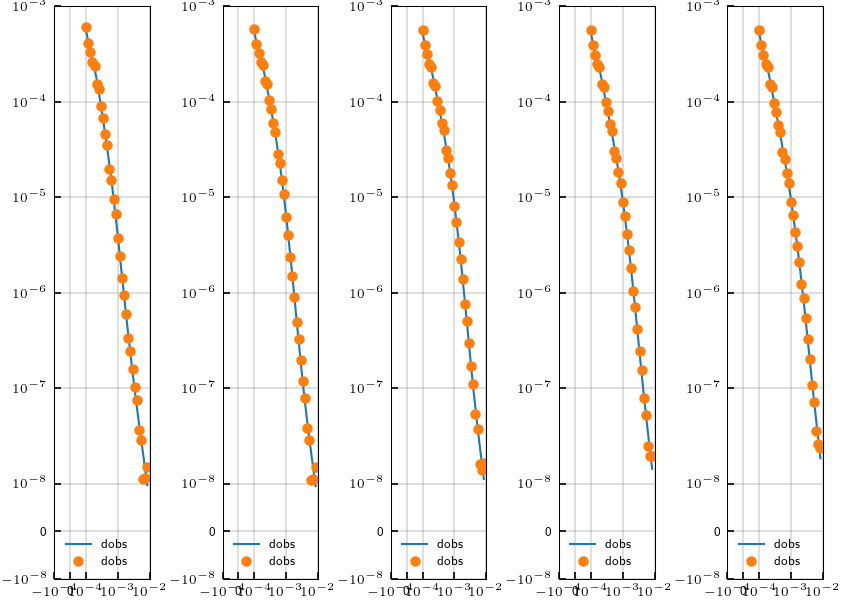

In [21]:
fig, ax= plt.subplots(1,nmodel, figsize=(textwidth,4))
dobs_cmb =[]
ax= ax.flatten()
dobs_cmb = []
 # For reproducibility
for i in range(nmodel):
   # np.random.seed(i) # if you wanto have different noise for each model 
    # if you want the same noise for each model

   np.random.seed(1)
   # Calculate noise floor and relative erro at each window
   mvec_obs = m_trues[i]
   dobs_clean=sim_obs.dpred(mvec_obs)
   noise_floor = data_noise_floor
   noise_relative = relative_error * np.abs(dobs_clean)

   # Combine the two sources of noise
   total_noise = np.sqrt(noise_floor**2 + noise_relative**2)

   # Add the combined noise to the clean data
   dobs = dobs_clean +  np.random.randn(len(dobs_clean)) * total_noise

   dobs_cmb.append(dobs)
   ax[i]=PL_decay.plpl_plot(x= windows_cen-rmp_time,y=dobs_clean, 
      label="dobs", color="C0", linestyle="-",ax=ax[i]
   )
   ax[i]=PL_decay.plpl_plot(x= windows_cen-rmp_time,y=dobs, 
      label="dobs", color="C1", marker="o",markersize=4,linestyle="",ax=ax[i]
   )
   ax[i]= PL_decay.pl_axes(ax[i])
   ax[i]= PL_decay.pl_axes_x(ax[i])
#for ax in ax:

   ax[i].legend()




# Inversion with Bandwidth-limied model

In [22]:
np.tile([0,1,1],3)

array([0, 1, 1, 0, 1, 1, 0, 1, 1])

In [23]:
taus_strt_log = -4.00
taus_end_log  = -1.75#np.r_[-2.25, -2.25, -2.25]
taus_end = 10**taus_end_log
taus_strt = 10**taus_strt_log
taus_step_log = 0.25

ntau =  int((taus_end_log - taus_strt_log)/taus_step_log) +1
taus= np.logspace(taus_strt_log, taus_end_log, ntau, endpoint=True)
print(ntau)
print(taus) 
nM_layer = ntau + 1

10
[0.0001     0.00017783 0.00031623 0.00056234 0.001      0.00177828
 0.00316228 0.00562341 0.01       0.01778279]


In [ ]:
m_ref 


empymod_model_sim = empymod_model_sim
sim_inv=empymod_IP_simulation(ip_model='DDR',chgmin=0,
        model_base=empymod_model_sim, nlayer=nlayer,tx_height=tx_height,
        taus=taus, times=times_sim, smp_freq=smp_freq
    )
sim_inv.deepsea_fix_sea(res_sea=res_sea, eta_sea=eta_sea)
m_ref = np.r_[np.log(res_sea)*np.ones(nlayer-1),
              eta_sea*np.ones((nlayer-1)*ntau)] 


dpred_step= sim_inv.dpred(m_ref)
sim_inv.cut_off = smp_freq/2.0
dpred_LPF = sim_inv.dpred(m_ref)
sim_inv.filt_curr = filt_linrmp
dpred_rmp = sim_inv.dpred(m_ref)
sim_inv.window_mat=Window_mat
dpred_window = sim_inv.dpred(m_ref)
opt = Optimization(sim=sim_inv, dobs=dpred_window)
opt.get_Wd(ratio=relative_error, plateau=data_noise_floor )
Wd_ref= opt.Wd
J_ref = opt.J(m_ref)


In [25]:
bool_MtoP= np.tile([False] + [True] * (nlayer-1), nM_layer)
print(f"bool_MtoP: {bool_MtoP}")
diag_nP= np.diag(np.ones(sim_inv.nP))
Prj_m = diag_nP[:, bool_MtoP]


bool_MtoP: [False  True  True  True  True  True  True  True  True  True  True False
  True  True  True  True  True  True  True  True  True  True False  True
  True  True  True  True  True  True  True  True  True False  True  True
  True  True  True  True  True  True  True  True False  True  True  True
  True  True  True  True  True  True  True False  True  True  True  True
  True  True  True  True  True  True False  True  True  True  True  True
  True  True  True  True  True False  True  True  True  True  True  True
  True  True  True  True False  True  True  True  True  True  True  True
  True  True  True False  True  True  True  True  True  True  True  True
  True  True False  True  True  True  True  True  True  True  True  True
  True]


In [26]:
with np.printoptions(threshold=np.inf, linewidth=200):
    print(Prj_m)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.

In [27]:
sim_inv.nlayer_fix
print(sim_inv.Prj_m@m_ref + sim_inv.m_fix)

[-1.2039728 -1.2039728 -1.2039728 -1.2039728 -1.2039728 -1.2039728
 -1.2039728 -1.2039728 -1.2039728 -1.2039728 -1.2039728  0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.       

In [28]:
sim_inv.get_ip_model(m_ref)

{'res': array([0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3]),
 'rho_0': array([0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3]),
 'func_eta': <bound method empymod_IP_simulation.ddr of <masa_utils.empymod_IP_simulation object at 0x0000022A94A131D0>>,
 'm_0': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_1': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_2': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_3': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_4': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_5': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_6': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_7': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_8': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_9': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}

In [29]:
for j in range(nlayer-1):
    print(m_ref[j::nlayer-1])



[-1.2039728  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.       ]
[-1.2039728  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.       ]
[-1.2039728  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.       ]
[-1.2039728  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.       ]
[-1.2039728  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.       ]
[-1.2039728  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.       ]
[-1.2039728  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.       ]
[-1.2039728  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.       ]
[-1.2039728  0.         0.         0.         0.         0.
  0.

Define function to deactivate etas

In [30]:

WdJ=Wd_ref@J_ref
print(f"shape of WdJ: {WdJ.shape}")
assert WdJ.shape[1] == nM_layer*(nlayer-1)

shape of WdJ: (30, 110)


In [31]:
def plot_jacobian(WdJ,taus,ntau, bool_etas=None,ax=None, unit=False):
    colormap = plt.get_cmap("turbo")
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(5,3))
    colors = np.linspace(0, 1, ntau)
    rho0 = WdJ[:,0]
    con8 = -rho0
    sign_ip= -1
    ind_con = np.argmax(con8)
    ind_max = rho0.shape[0]-1
    if bool_etas is None:
        bool_etas = np.full(ntau, True)
    for j in range(ntau):
        color = colormap(colors[j])
        linewidth = 1
        linestyle ='-'
        markersize= 2.0
        # label = rf"$\Delta\eta_{{{j+1}}}, \tau_{{{j+1}}}: \SI{{{taus[j]:.1e}}}{{\second}}$"
        label = rf"$\Delta\eta_{{{j+1}}}, \tau_{{{j+1}}}: {sci_latex(taus[j], prec=1)} s$"
        y = WdJ[:, j + 1]
        ind_eta = np.argmax(sign_ip*y)
        if bool_etas[j]: # only plot the jacobian for the parameters that are being inverted
            linewidth = 1
            linestyle ='-'
            marker = ""
            markersize = 2
            alpha = 1.0
            if ind_eta > ind_con and ind_eta< ind_max:
                ax = PL_jac.semiply(
                    x=windows_cen[ind_eta] - rmp_time,
                    y=y[ind_eta],
                    color=color,
                    linestyle="",
                    marker="o",
                    markersize=markersize,
                    ax=ax
                )

        else:
            linewidth = 0.5
            linestyle ='-.'
            marker = ""
            markersize = 2
            alpha = 0.5

        ax = PL_jac.semiply(
            x=windows_cen - rmp_time,
            y=y,
            color=color,
            linestyle=linestyle,
            label=label,
            linewidth=linewidth,
            ax=ax
        )
        ind_eta = np.argmax(sign_ip*y)
    ax=PL_jac.semiply(
        windows_cen-rmp_time, rho0,color="k",label=r"+$\Delta\log{\rho_0}$",ax=ax,
            linestyle="--", linewidth=1#, marker="o",markersize=4
            )

    ax=PL_jac.semiply(
        windows_cen-rmp_time, -rho0,color="k",label=r"-$\Delta\log{\rho_0}$",ax=ax,
            linestyle="-.", linewidth=1#, marker="o",markersize=4
            )
    ax = PL_jac.semiply(
        x=windows_cen[ind_con] - rmp_time, y=rho0[ind_con], color="k",
        linestyle="", marker="o", markersize=2.0, ax=ax
    )
    # ax.axvline(x=windows_maxrho0-rmp_time,  color="k", linestyle=":", label=r"peak of $-\Delta\log{\rho_0}$")
    ax= PL_jac.pl_axes(ax)
    ax.set_xlabel("Time (s)")
    ax.set_title(fr"$W_dJ$")
    return ax

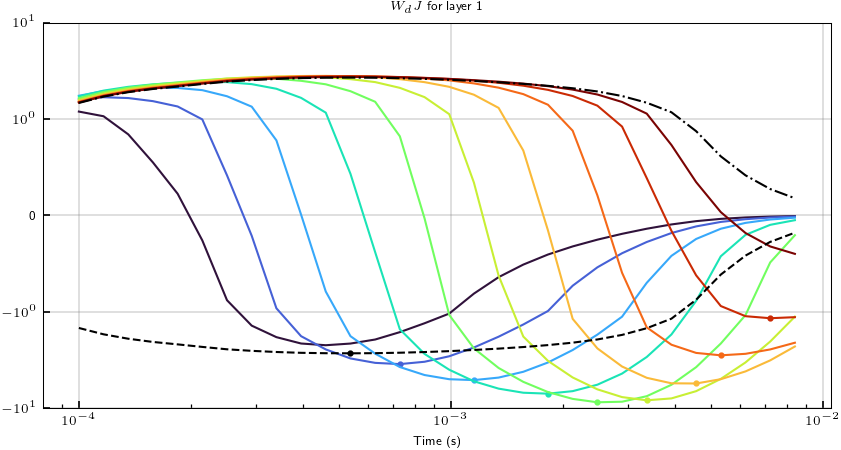

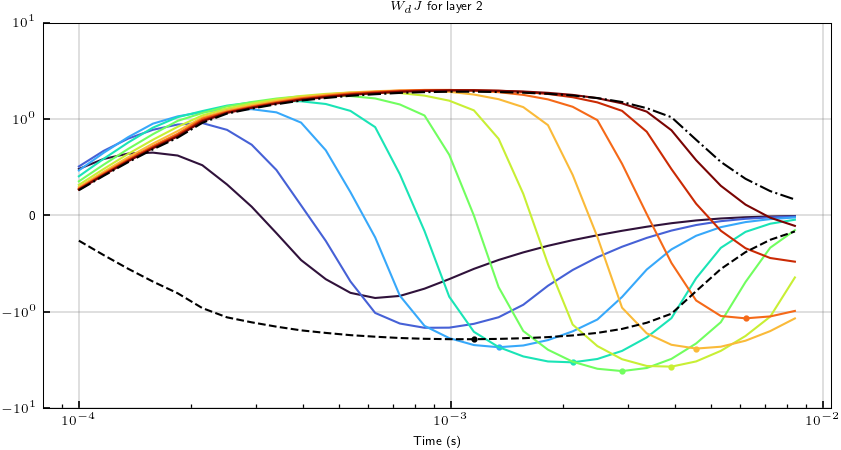

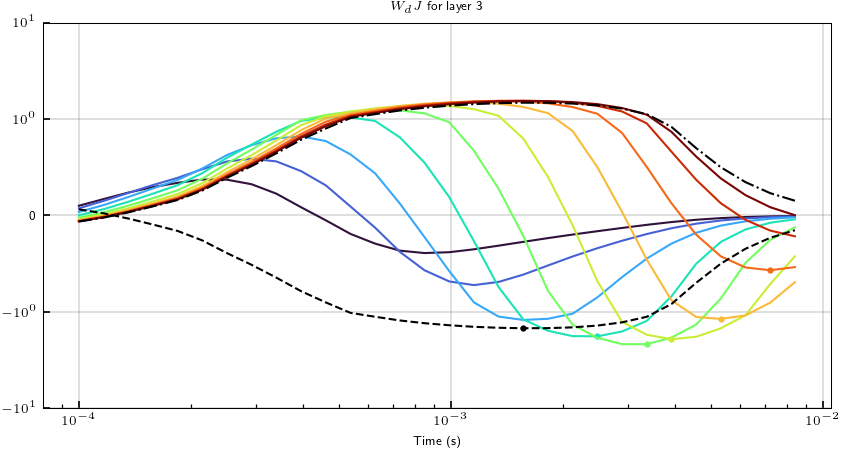

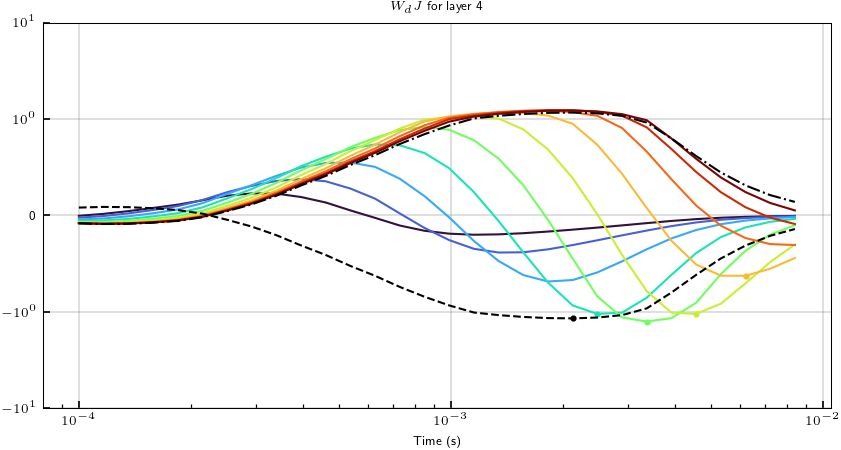

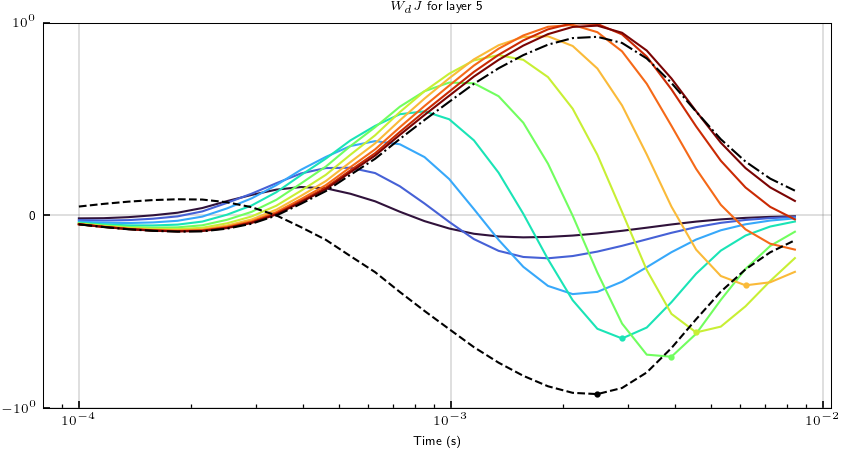

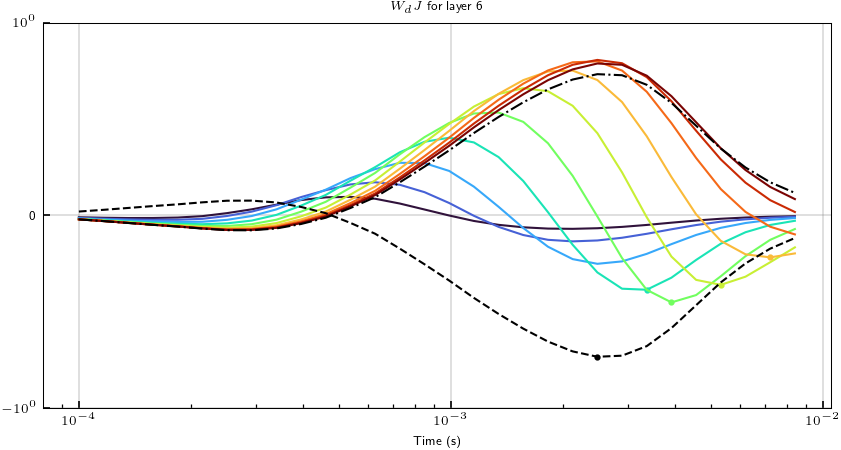

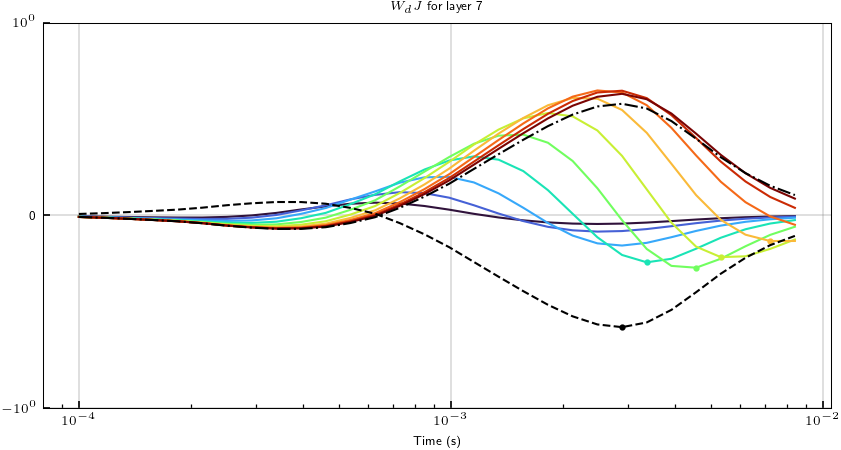

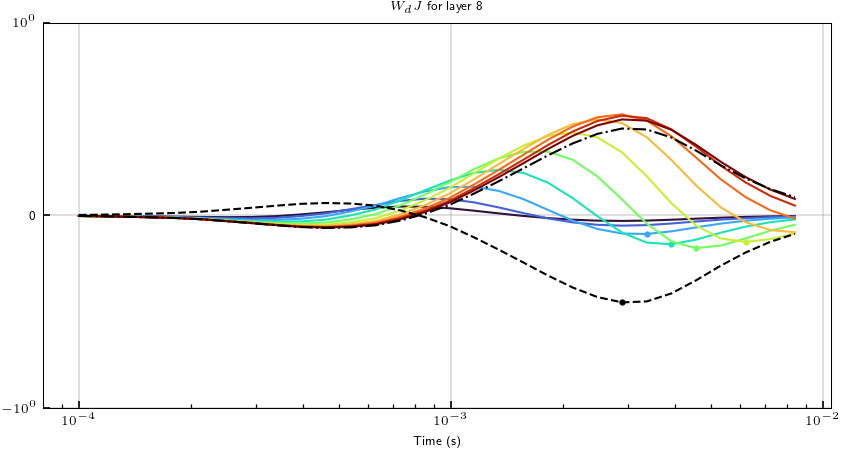

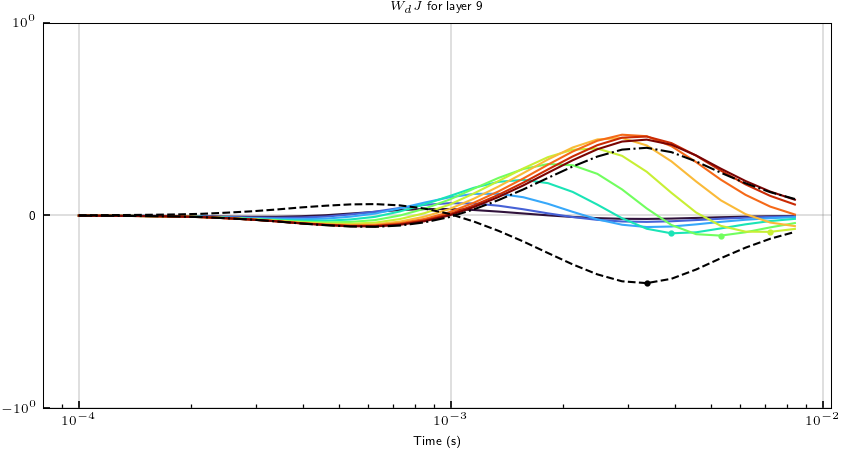

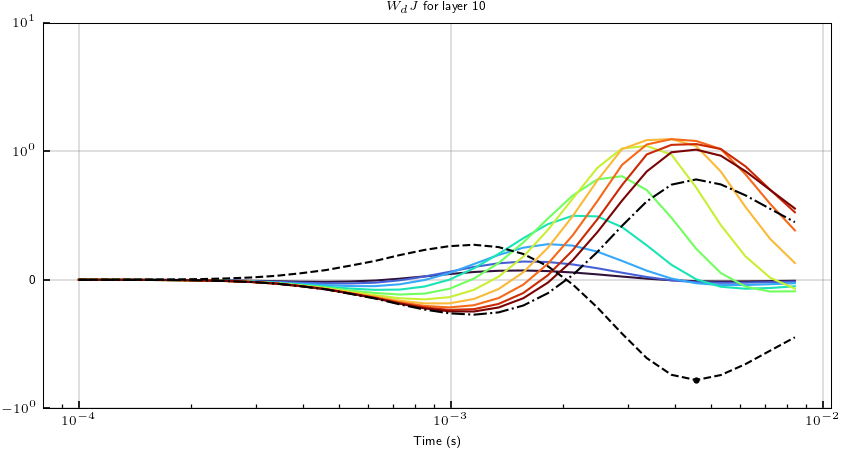

In [32]:

for i in range(nlayer-1):
    fig, ax = plt.subplots(1,1, figsize=(textwidth,3))
    WdJ_layer = WdJ[:, i::nlayer-1]
    # print(f"shape of WdJ_layer: {WdJ_layer.shape}")
    ax = plot_jacobian(WdJ_layer, taus, ntau, ax=ax, unit=False)
    ax.set_title(fr"$W_dJ$ for layer {i+1}")

define function to deactivate etas

In [33]:
def activate_etas(WdJ, ntau=None, threshold_ratio=1e-6):

    if ntau  is not None:
        assert WdJ.shape[1] == ntau +1, "The number of columns in WdJ should be equal to ntau + 1 (for rho0)"
    else:
        ntau = WdJ.shape[1] -1
    rho0 = WdJ[:,0]
    con8 = -WdJ[:,0]
    ind = np.argmax(np.abs(con8))
    sign_ip = -np.sign(con8[ind])
    # print(f"sign of con8 at the peak: {sign_ip}, index: {ind}")
    threshold = threshold_ratio * np.max(np.abs(rho0))
    boole_etas = np.full(ntau, False)
    # eta_max = 0
    ind_max = con8.shape[0]-1
    for k in range(ntau):
        etak = WdJ[:, k+1]
        ind_eta = np.argmax(sign_ip*etak)
        # print(f"k={k}, ind_etak: {ind_eta}, ind_rho0: {ind}")
        if ind_eta > ind and ind_eta< ind_max:
            # print(ind_eta, ind_max)
            if np.any ((etak[ind:]+con8[ind:]) *sign_ip > threshold):
                # eta_max_tmp = etak[-1] *sign_ip
                # if eta_max_tmp >= eta_max - threshold:
                boole_etas[k] = True
                # eta_max = eta_max_tmp
    return boole_etas


In [34]:
p_meta_list = []
for j in range(ntau+1):
    for i in range(nlayer):
        if j==0:
            p_meta_list.append(["rho_0",i]) # rho0, ith layer
        else:
            p_meta_list.append([f"m_{j}",i]) # eta_j, ith layer


In [35]:
p_meta_list

[['rho_0', 0],
 ['rho_0', 1],
 ['rho_0', 2],
 ['rho_0', 3],
 ['rho_0', 4],
 ['rho_0', 5],
 ['rho_0', 6],
 ['rho_0', 7],
 ['rho_0', 8],
 ['rho_0', 9],
 ['rho_0', 10],
 ['m_1', 0],
 ['m_1', 1],
 ['m_1', 2],
 ['m_1', 3],
 ['m_1', 4],
 ['m_1', 5],
 ['m_1', 6],
 ['m_1', 7],
 ['m_1', 8],
 ['m_1', 9],
 ['m_1', 10],
 ['m_2', 0],
 ['m_2', 1],
 ['m_2', 2],
 ['m_2', 3],
 ['m_2', 4],
 ['m_2', 5],
 ['m_2', 6],
 ['m_2', 7],
 ['m_2', 8],
 ['m_2', 9],
 ['m_2', 10],
 ['m_3', 0],
 ['m_3', 1],
 ['m_3', 2],
 ['m_3', 3],
 ['m_3', 4],
 ['m_3', 5],
 ['m_3', 6],
 ['m_3', 7],
 ['m_3', 8],
 ['m_3', 9],
 ['m_3', 10],
 ['m_4', 0],
 ['m_4', 1],
 ['m_4', 2],
 ['m_4', 3],
 ['m_4', 4],
 ['m_4', 5],
 ['m_4', 6],
 ['m_4', 7],
 ['m_4', 8],
 ['m_4', 9],
 ['m_4', 10],
 ['m_5', 0],
 ['m_5', 1],
 ['m_5', 2],
 ['m_5', 3],
 ['m_5', 4],
 ['m_5', 5],
 ['m_5', 6],
 ['m_5', 7],
 ['m_5', 8],
 ['m_5', 9],
 ['m_5', 10],
 ['m_6', 0],
 ['m_6', 1],
 ['m_6', 2],
 ['m_6', 3],
 ['m_6', 4],
 ['m_6', 5],
 ['m_6', 6],
 ['m_6', 7],
 ['m_6', 8

In [36]:
bool_MtoP = np.r_[np.full(sim_inv.nP,False)] 
m_meta_list = []
bool_etas_cmb = []
for i in range(nlayer-1):
    WdJ_layer = WdJ[:, i::nlayer-1]
    bool_etas= activate_etas(WdJ=WdJ_layer, ntau=ntau)
    print(f"layer {i}: {bool_etas}")
    bool_etas_cmb.append(bool_etas)
    bool_MtoP_layer = np.r_[True, bool_etas] 
    # print(bool_MtoP[1+i::nlayer].shape, bool_MtoP_layer.shape)
    bool_MtoP[1+i::nlayer] = bool_MtoP_layer
    m_meta_list_layer = []
    m_meta_list_layer.append(["rho_0",i+1]) # rho0, ith layer
    for j in range(ntau):
        if bool_etas[j]:
            m_meta_list_layer.append([f"m_{j}",i+1]) # eta_j, ith layer
    m_meta_list.append(m_meta_list_layer)



layer 0: [False  True  True  True  True  True  True  True  True False]
layer 1: [False False  True  True  True  True  True  True False False]
layer 2: [False False False  True  True  True  True  True False False]
layer 3: [False False False False  True  True  True False False False]
layer 4: [False False False False  True  True  True False False False]
layer 5: [False False False False False  True  True False False False]
layer 6: [False False False False False  True  True False False False]
layer 7: [False False False False False False False False False False]
layer 8: [False False False False False False False False False False]
layer 9: [False False False False False False False False False False]


In [37]:
m_meta_list = []
for i, meta in enumerate(p_meta_list):
    if bool_MtoP[i]:
        m_meta_list.append(meta)
print(m_meta_list)
sim_inv.m_meta_list = m_meta_list

[['rho_0', 1], ['rho_0', 2], ['rho_0', 3], ['rho_0', 4], ['rho_0', 5], ['rho_0', 6], ['rho_0', 7], ['rho_0', 8], ['rho_0', 9], ['rho_0', 10], ['m_2', 1], ['m_3', 1], ['m_3', 2], ['m_4', 1], ['m_4', 2], ['m_4', 3], ['m_5', 1], ['m_5', 2], ['m_5', 3], ['m_5', 4], ['m_5', 5], ['m_6', 1], ['m_6', 2], ['m_6', 3], ['m_6', 4], ['m_6', 5], ['m_6', 6], ['m_6', 7], ['m_7', 1], ['m_7', 2], ['m_7', 3], ['m_7', 4], ['m_7', 5], ['m_7', 6], ['m_7', 7], ['m_8', 1], ['m_8', 2], ['m_8', 3], ['m_9', 1]]


In [38]:
m_meta = np.array(m_meta_list, dtype=object)
print(m_meta[38])

['m_9' 1]


In [39]:
indices_r = np.arange(sim_inv.nM_r)

In [40]:
indices_m_list = []

for i in range(nlayer-1):
    indices_m_list.append(np.where(m_meta[:,1]==i+1)[0])
print(f"indices_m_list: {indices_m_list}")
sim_inv.indices_m_list = indices_m_list

indices_m_list: [array([ 0, 10, 11, 13, 16, 21, 28, 35, 38]), array([ 1, 12, 14, 17, 22, 29, 36]), array([ 2, 15, 18, 23, 30, 37]), array([ 3, 19, 24, 31]), array([ 4, 20, 25, 32]), array([ 5, 26, 33]), array([ 6, 27, 34]), array([7]), array([8]), array([9])]


In [41]:
for indices_m in indices_m_list:
    print(indices_m.size)
    print(f"indices_m: {indices_m}, \n m_meta: {m_meta[indices_m]}")

9
indices_m: [ 0 10 11 13 16 21 28 35 38], 
 m_meta: [['rho_0' 1]
 ['m_2' 1]
 ['m_3' 1]
 ['m_4' 1]
 ['m_5' 1]
 ['m_6' 1]
 ['m_7' 1]
 ['m_8' 1]
 ['m_9' 1]]
7
indices_m: [ 1 12 14 17 22 29 36], 
 m_meta: [['rho_0' 2]
 ['m_3' 2]
 ['m_4' 2]
 ['m_5' 2]
 ['m_6' 2]
 ['m_7' 2]
 ['m_8' 2]]
6
indices_m: [ 2 15 18 23 30 37], 
 m_meta: [['rho_0' 3]
 ['m_4' 3]
 ['m_5' 3]
 ['m_6' 3]
 ['m_7' 3]
 ['m_8' 3]]
4
indices_m: [ 3 19 24 31], 
 m_meta: [['rho_0' 4]
 ['m_5' 4]
 ['m_6' 4]
 ['m_7' 4]]
4
indices_m: [ 4 20 25 32], 
 m_meta: [['rho_0' 5]
 ['m_5' 5]
 ['m_6' 5]
 ['m_7' 5]]
3
indices_m: [ 5 26 33], 
 m_meta: [['rho_0' 6]
 ['m_6' 6]
 ['m_7' 6]]
3
indices_m: [ 6 27 34], 
 m_meta: [['rho_0' 7]
 ['m_6' 7]
 ['m_7' 7]]
1
indices_m: [7], 
 m_meta: [['rho_0' 8]]
1
indices_m: [8], 
 m_meta: [['rho_0' 9]]
1
indices_m: [9], 
 m_meta: [['rho_0' 10]]


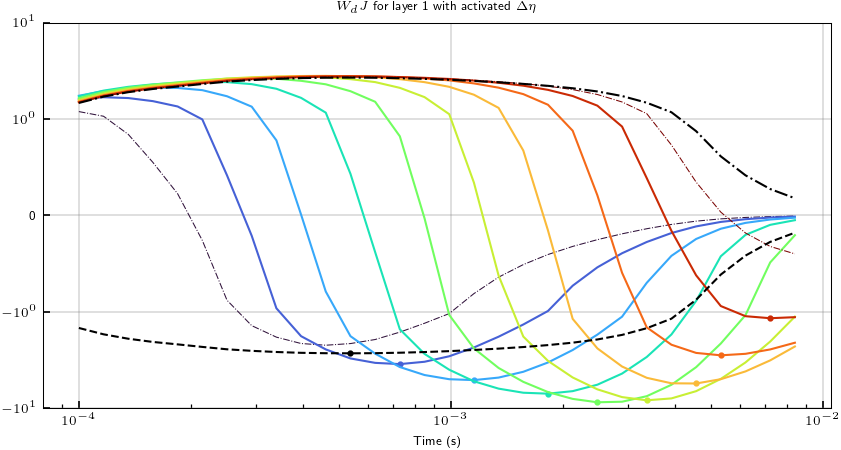

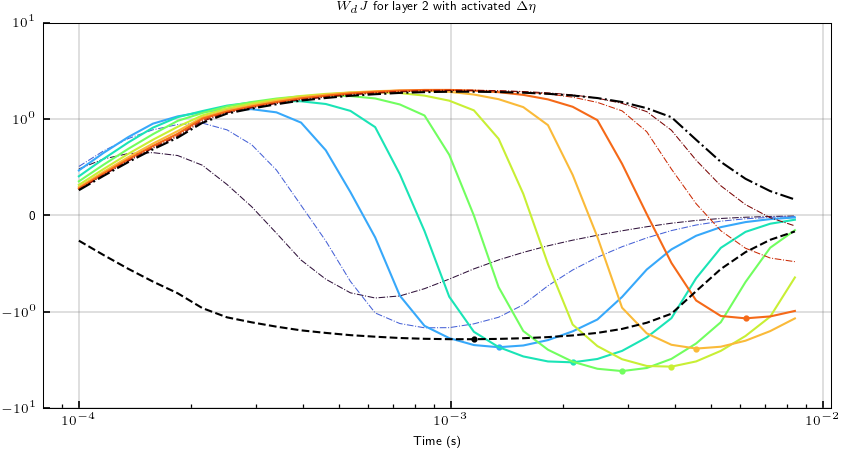

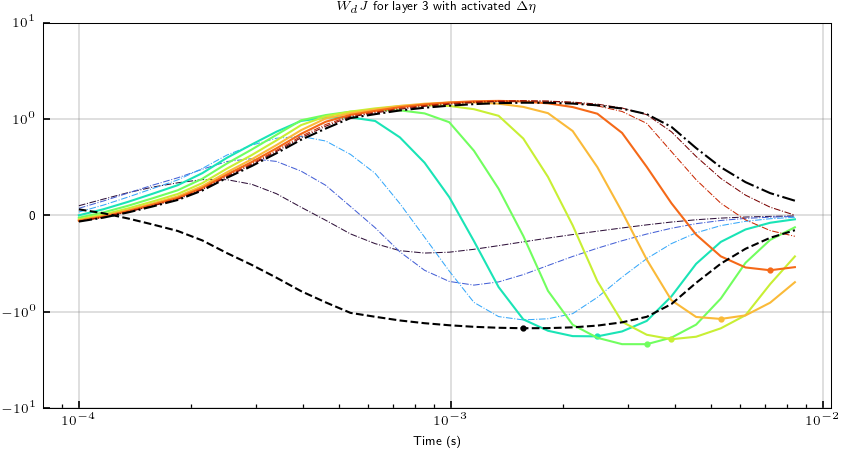

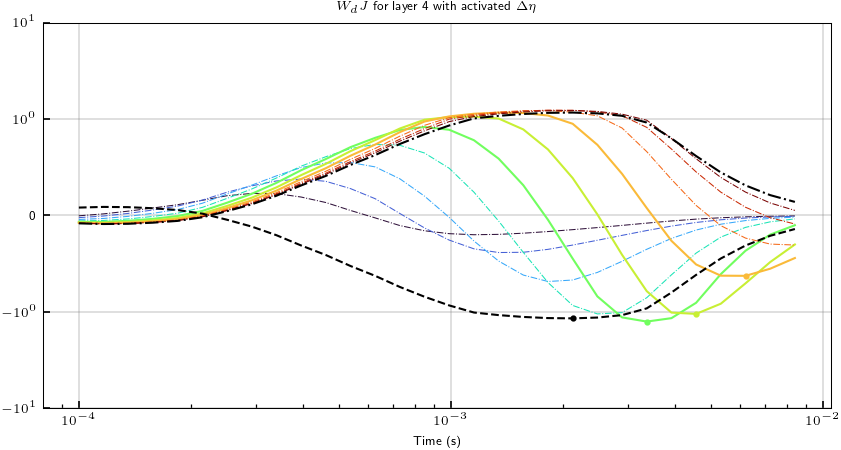

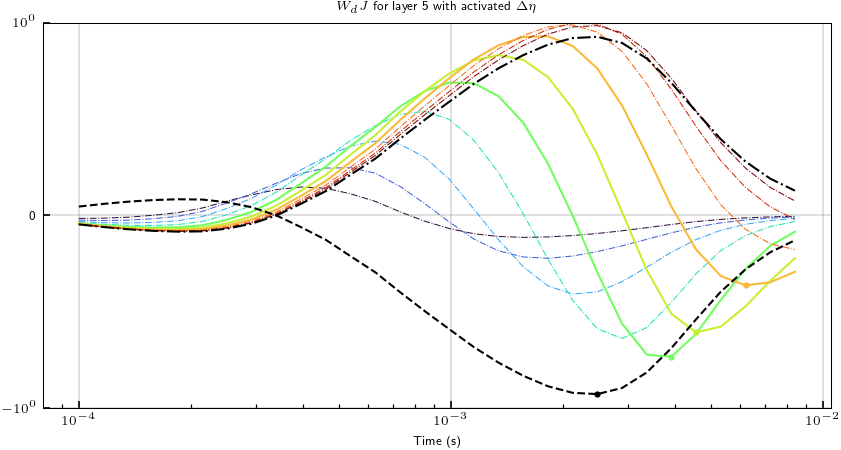

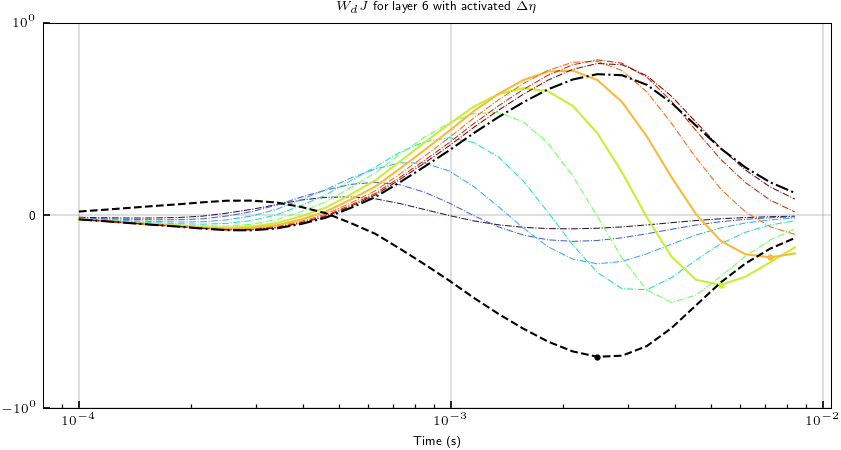

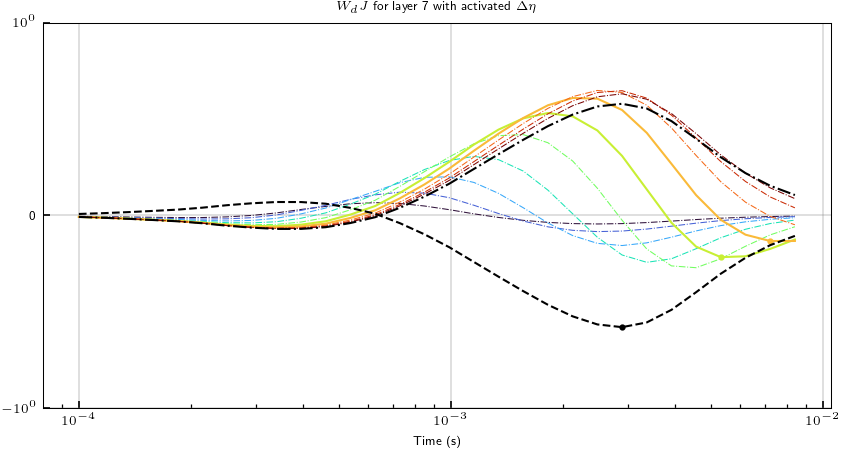

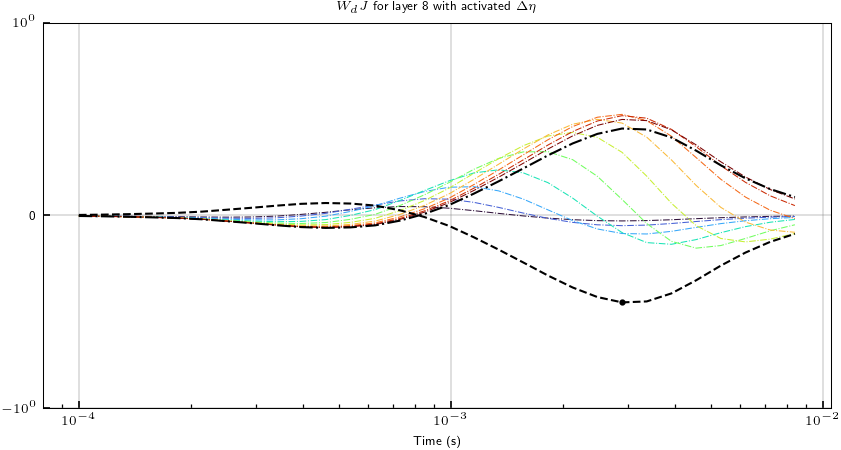

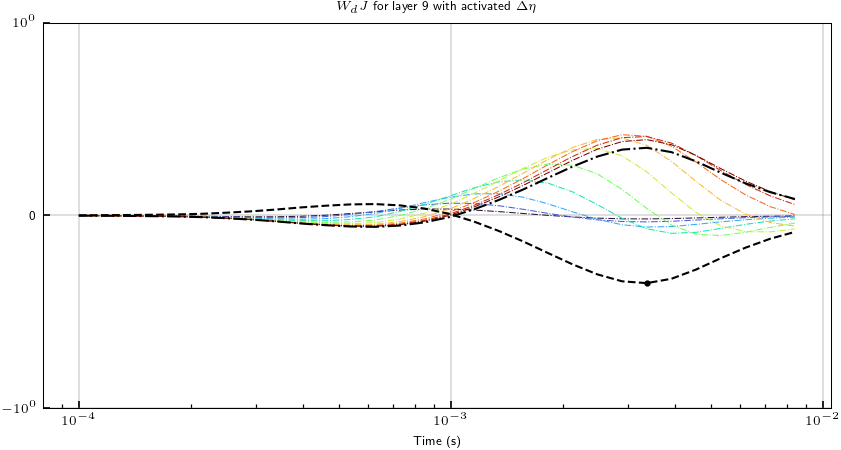

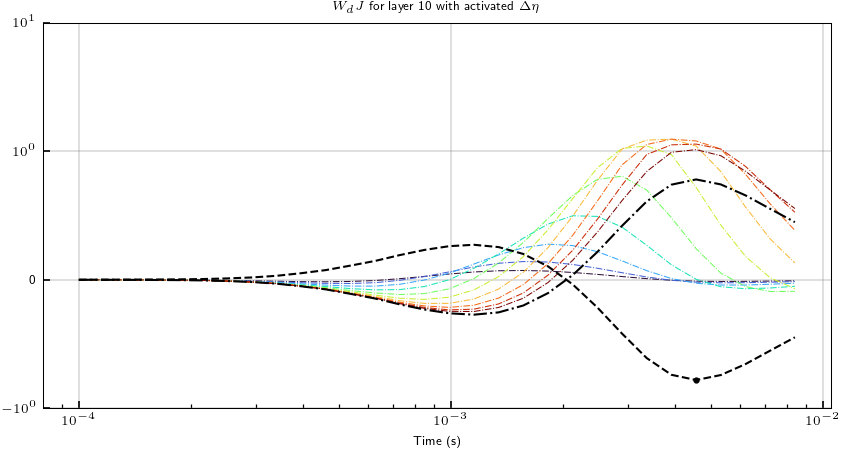

In [42]:

for i in range(nlayer-1):
    fig, ax = plt.subplots(1,1, figsize=(textwidth,3))
    WdJ_layer = WdJ[:, i::nlayer-1]
    # print(f"shape of WdJ_layer: {WdJ_layer.shape}")
    ax = plot_jacobian(WdJ_layer, taus, ntau,bool_etas=bool_etas_cmb[i], ax=ax, unit=False)
    ax.set_title(fr"$W_dJ$ for layer {i+1} with activated $\Delta\eta$")

In [43]:
print(bool_MtoP)

[False  True  True  True  True  True  True  True  True  True  True False
 False False False False False False False False False False False  True
 False False False False False False False False False False  True  True
 False False False False False False False False False  True  True  True
 False False False False False False False False  True  True  True  True
  True False False False False False False  True  True  True  True  True
  True  True False False False False  True  True  True  True  True  True
  True False False False False  True  True  True False False False False
 False False False False  True False False False False False False False
 False False False False False False False False False False False False
 False]


In [44]:
diag_nP= np.diag(np.ones(sim_inv.nP))
Prj_m = diag_nP[:,bool_MtoP]
sim_inv.Prj_m = Prj_m
sim_inv.nM = Prj_m.shape[1]
sim_inv.nM_r = sim_inv.nlayer-1
sim_inv.nM_m= bool_MtoP.sum()-(sim_inv.nlayer-1)

In [45]:
print(f"sim_inv.nM: {sim_inv.nM}")
print(f"sim_inv.nM_m: {sim_inv.nM_m}")
print(f"sim_inv.nM_r: {sim_inv.nM_r}")
print(f"Prj_m: {sim_inv.Prj_m.shape}")
print(f"sim_inv.m_fix.shape: {sim_inv.m_fix.shape}")

sim_inv.nM: 39
sim_inv.nM_m: 29
sim_inv.nM_r: 10
Prj_m: (121, 39)
sim_inv.m_fix.shape: (121,)


In [46]:
with np.printoptions(threshold=np.inf, linewidth=200):
    print(Prj_m)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.

In [47]:
print(sim_inv.Prj_m.shape)
print(sim_inv.m_fix.shape)

(121, 39)
(121,)


In [48]:
m_ref = np.r_[np.log(res_sea)*np.ones(sim_inv.nM_r),
              eta_sea*np.ones(sim_inv.nM_m)] 
# m_ref = np.r_[np.log(0.5)*np.ones(sim_inv.nM_r),
#               0.1*np.ones(sim_inv.nM_m)] 

print(m_ref.shape)
sim_inv.dpred(m_ref)
sim_inv.get_ip_model(m_ref)

(39,)


{'res': array([0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3]),
 'rho_0': array([0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3]),
 'func_eta': <bound method empymod_IP_simulation.ddr of <masa_utils.empymod_IP_simulation object at 0x0000022A94A131D0>>,
 'm_0': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_1': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_2': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_3': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_4': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_5': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_6': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_7': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_8': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_9': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}

In [49]:

m_test = np.r_[np.log(1e-5)*np.ones(sim_inv.nM_r),
              100*(np.random.random(sim_inv.nM_m)-0.5)] 
# print(sim_inv.get_ip_model(m_test))
m_test_clip = sim_inv.project_convex_set(m_test)
print(sim_inv.get_ip_model(m_test_clip))
# sim_inv.dpred(m_ref)


{'res': array([0.3  , 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001,
       0.001, 0.001]), 'rho_0': array([0.3  , 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001,
       0.001, 0.001]), 'func_eta': <bound method empymod_IP_simulation.ddr of <masa_utils.empymod_IP_simulation object at 0x0000022A94A131D0>>, 'm_0': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_1': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_2': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_3': array([0.        , 0.18010559, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        ]), 'm_4': array([0.        , 0.        , 0.        , 0.45035264, 0.        ,
       0.45020576, 0.        , 0.        , 0.        , 0.        ,
       0.        ]), 'm_5': array([0.        , 0.18010559, 0.        , 0.        , 0.45020576,
       0.        , 0.        , 0.9       , 0.        , 0.        ,
       0.        ]), 'm_6': arr

In [50]:
Prj_RM = np.zeros((2*nlayer, (1+ntau)*nlayer))
print(Prj_RM.shape)
Prj_RM [:nlayer, :nlayer] = np.eye(nlayer)
for i in range(nlayer):
    Prj_RM[nlayer+i, nlayer+i::nlayer] = 1.0

(22, 121)


In [51]:
# 
depth = sim_inv.model_base["depth"]
depth_ext= np.r_[depth[0]-(depth[1]-depth[0]),depth, 2*depth[-1]-depth[-2]]
x = (depth_ext[:-1] + depth_ext[1:]) / 2
delta_x = np.diff(x)
elm1 = 1/delta_x
elm2 = np.sqrt(delta_x)
elm2[0] = 0.0
Wx_p_block = np.zeros((nlayer-1, nlayer))
Wx_p_block[:,:-1] = -np.diag(elm2*elm1)
Wx_p_block[:,1:] += np.diag(elm2*elm1)
Wx_p = np.zeros((2*(nlayer-1),2*nlayer))
Wx_p[:nlayer-1,:nlayer] = Wx_p_block
Wx_p[nlayer-1:,nlayer:] = 1.0*Wx_p_block


In [52]:
depth

array([ 4.,  6.,  8., 10., 12., 14., 16., 18., 20., 22.])

In [53]:
with np.printoptions(threshold=np.inf, linewidth=200):
    print(Wx_p)

[[-0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [-0.         -0.70710678  0.70710678  0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [-0.          0.         -0.70710678  0.70710678  0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.        ]
 [-0.          0.          0.         -0.70710678  0.70710678  0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.
   0.          0.          0.  

In [54]:
Wx_p@sim_inv.Prj_RM@(sim_inv.Prj_m@m_ref + sim_inv.m_fix)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0.])

In [55]:
Wx = Wx_p@Prj_RM@Prj_m

In [56]:
with np.printoptions(threshold=np.inf, linewidth=200):
    print(Wx)

[[ 0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.          0.        ]
 [-0.70710678  0.70710678  0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.          0.        ]
 [ 0.         -0.70710678  0.70710678  0.          0.          0.          0.     

In [57]:
Wx@m_ref 

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0.])

In [58]:
niter = 50
stol=1e-3
coolingFactor =2.0
coolingRate = 2
mu=1e-2
beta0_ratio = 1
alphas, alphax = 1.0, 1.0
Ws_threshold=1e-3

In [59]:
dobs_cmb

[array([6.02627532e-04, 4.14857016e-04, 3.29835838e-04, 2.59397994e-04,
        2.35225849e-04, 1.53201872e-04, 1.35906999e-04, 8.94751158e-05,
        6.77758557e-05, 4.56281806e-05, 3.54891414e-05, 1.99383076e-05,
        1.51290894e-05, 9.58901563e-06, 6.62196235e-06, 3.75417598e-06,
        2.40974035e-06, 1.43931375e-06, 9.36707072e-07, 5.95575637e-07,
        3.39395740e-07, 2.47851764e-07, 1.59925605e-07, 1.03138527e-07,
        7.44334818e-08, 3.68777574e-08, 2.86121047e-08, 1.11434137e-08,
        1.14038093e-08, 1.49858457e-08]),
 array([5.79943912e-04, 4.03357093e-04, 3.25866974e-04, 2.61425452e-04,
        2.42401465e-04, 1.63425127e-04, 1.52066266e-04, 1.04794318e-04,
        8.35558014e-05, 5.94681807e-05, 4.85140079e-05, 2.86782262e-05,
        2.27056458e-05, 1.50264809e-05, 1.07187534e-05, 6.20441688e-06,
        4.01246051e-06, 2.37421646e-06, 1.50223212e-06, 9.10064561e-07,
        4.88979875e-07, 3.27623861e-07, 1.95226732e-07, 1.17475058e-07,
        7.97071402e-08

In [69]:
models_rec = []
dpreds = []
error_prgs = []
model_prgs = []
dinit_refs = []
data_prgs =[]
for i in range(nmodel):
    m_ref = m_ref
    dobs = dobs_cmb[i]
    opt = Optimization(
        sim=sim_inv, dobs=dobs, 
        alphas=alphas, alphax=alphax, 
        Ws_threshold=Ws_threshold
        )
    opt.get_Wd(ratio=relative_error, plateau=noise_floor)
    Wd=opt.Wd
    smallness = np.ones(sim_inv.nM)
    opt.get_Ws(smallness=smallness)
    opt.Wx = Wx
    beta0 = opt.BetaEstimate_byEig(
        mvec=m_ref, update_Wsen=True, beta0_ratio=beta0_ratio)
    print(beta0)
    opt.set_beta_schedule(
        niter=niter, beta0=beta0, coolingRate=coolingRate, coolingFactor=coolingFactor
    )
    mpred = opt.GaussNewton(
    mvec_init=m_ref,update_Wsen=True,stol=stol,mu=mu
    )
    
    dinit_refs.append(opt.dpred(m_ref))
    models_rec.append(mpred)
    dpreds.append(opt.dpred(mpred))
    error_prgs.append(opt.error_prg)
    model_prgs.append(opt.mvec_prg)
    data_prgs.append(opt.data_prg)


827910.7237515794
  1, beta:8.3e+05, step:5.0e-01, g:3.0e+03, phid:1.2e+03, phim:1.5e-05, f:1.3e+03 
  2, beta:8.3e+05, step:2.0e-03, g:8.3e+03, phid:1.2e+03, phim:1.6e-05, f:1.3e+03 
  3, beta:4.1e+05, step:5.0e-01, g:4.9e+03, phid:1.2e+03, phim:9.5e-05, f:1.3e+03 
  4, beta:4.1e+05, step:3.9e-03, g:1.0e+04, phid:1.2e+03, phim:9.5e-05, f:1.3e+03 
  5, beta:2.1e+05, step:5.0e-01, g:5.7e+03, phid:1.2e+03, phim:3.9e-04, f:1.2e+03 
  6, beta:2.1e+05, step:7.8e-03, g:1.0e+04, phid:1.2e+03, phim:3.9e-04, f:1.2e+03 
  7, beta:1.0e+05, step:5.0e-01, g:5.7e+03, phid:1.1e+03, phim:1.4e-03, f:1.2e+03 
  8, beta:1.0e+05, step:1.6e-02, g:9.6e+03, phid:1.1e+03, phim:1.4e-03, f:1.2e+03 
  9, beta:5.2e+04, step:5.0e-01, g:5.4e+03, phid:9.4e+02, phim:4.4e-03, f:1.2e+03 
 10, beta:5.2e+04, step:1.2e-01, g:8.3e+03, phid:9.2e+02, phim:4.8e-03, f:1.2e+03 
 11, beta:2.6e+04, step:1.0e+00, g:4.8e+03, phid:5.2e+02, phim:2.0e-02, f:1.0e+03 
 12, beta:2.6e+04, step:5.0e-01, g:7.4e+03, phid:4.8e+02, phim:2.1e-0

In [61]:
rd = opt.Wd@(dobs_cmb[0]-opt.dpred(m_ref))
print(f"phid: 0.5*rd@rd: {0.5*rd@rd}")

phid: 0.5*rd@rd: 1261.662339506025


In [62]:
opt.dpred(m_ref)

array([4.47369760e-04, 3.28569265e-04, 2.51273562e-04, 1.98070923e-04,
       1.59869925e-04, 1.20713989e-04, 8.63926393e-05, 6.45359158e-05,
       4.70797854e-05, 3.36806907e-05, 2.51129999e-05, 1.79318608e-05,
       1.32628393e-05, 9.25922990e-06, 6.57453579e-06, 4.66241934e-06,
       3.23926190e-06, 2.27698120e-06, 1.59969176e-06, 1.11402761e-06,
       7.76127566e-07, 5.39328401e-07, 3.73065627e-07, 2.57249254e-07,
       1.76996778e-07, 1.21827541e-07, 8.36599858e-08, 5.77567535e-08,
       3.95743776e-08, 2.71145897e-08])

In [68]:
sim_inv.m_fix

array([-1.2039728,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.    

In [ ]:
opt.sim.get_ip_model(m_ref)

{'res': array([0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3]),
 'rho_0': array([0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3]),
 'func_eta': <bound method empymod_IP_simulation.ddr of <masa_utils.empymod_IP_simulation object at 0x0000022A94A131D0>>,
 'm_0': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_1': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_2': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_3': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_4': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_5': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_6': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_7': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_8': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm_9': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 'm': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}

In [67]:
sim_inv.Prj_m@(m_ref)+sim_inv.m_fix

array([-1.2039728, -1.2039728, -1.2039728, -1.2039728, -1.2039728,
       -1.2039728, -1.2039728, -1.2039728, -1.2039728, -1.2039728,
       -1.2039728,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.       ,
        0.       ,  0.       ,  0.       ,  0.       ,  0.    

In [66]:
dobs_cmb[0]

array([6.02627532e-04, 4.14857016e-04, 3.29835838e-04, 2.59397994e-04,
       2.35225849e-04, 1.53201872e-04, 1.35906999e-04, 8.94751158e-05,
       6.77758557e-05, 4.56281806e-05, 3.54891414e-05, 1.99383076e-05,
       1.51290894e-05, 9.58901563e-06, 6.62196235e-06, 3.75417598e-06,
       2.40974035e-06, 1.43931375e-06, 9.36707072e-07, 5.95575637e-07,
       3.39395740e-07, 2.47851764e-07, 1.59925605e-07, 1.03138527e-07,
       7.44334818e-08, 3.68777574e-08, 2.86121047e-08, 1.11434137e-08,
       1.14038093e-08, 1.49858457e-08])

In [ ]:
Ws = opt.Ws
print(np.diag(Ws))

[0.21951031 0.24886389 0.16787129 0.14287335 0.10435866 0.07429628
 0.04971213 0.02462105 0.01600619 0.03276336 0.27105974 0.34014141
 0.5456096  0.42311607 0.75155557 0.26552236 0.55020628 0.92606122
 0.34644185 0.21872064 0.12637347 0.61812855 1.         0.36615357
 0.23647157 0.1379453  0.0826778  0.05698004 0.53549082 0.936763
 0.32552544 0.22529444 0.13828985 0.0939387  0.06614751 0.39523692
 0.81938025 0.27614189 0.30565166]


In [ ]:
phid_star=0.5*len(windows_cen)
models_rec_phid = []
models_rec_phid_R = []
models_rec_phid_M = []
dpreds_phid = []
phid_star_ratio =1.1
phid_itrs = []
for i in range(nmodel):
    model_prg= np.array(model_prgs[i])
    data_prg = np.array(data_prgs[i])
    error_prg = error_prgs[i]
    phid_prg = np.array(error_prg)[:,1]
    ind = phid_prg < phid_star*phid_star_ratio
    if np.sum(ind) == 0:
        ind = phid_prg == np.min(phid_prg)

        print(f"No iteration below phid_star, take min phid{np.where(ind)[0][0]}")
    phid_itr = np.where(ind)[0][0]
    models_rec_phid.append(model_prg[ind][0])
    dpreds_phid.append(data_prg[ind][0])
    phid_itrs.append(phid_itr)
    models_rec_phid_RM=(sim_inv.Prj_RM@(
        sim_inv.Prj_m@model_prg[ind][0]
        +sim_inv.m_fix))
    # models_rec_phid_R.append(models_rec_phid_RM[1:nlayer])
    # models_rec_phid_M.append(models_rec_phid_RM[nlayer+1:])
    
models_rec_phid_multi = np.array(models_rec_phid).flatten()
# models_rec_phid_multi_R = np.array(models_rec_phid_R).flatten()
# models_rec_phid_multi_M = np.array(models_rec_phid_M).flatten()


No iteration below phid_star, take min phid25


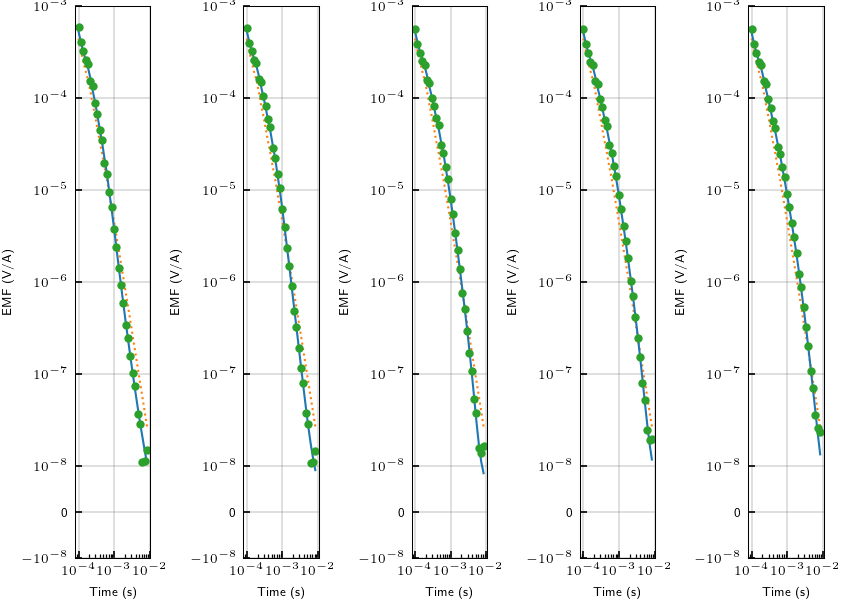

In [ ]:
fig, ax= plt.subplots(1,nmodel, figsize=(textwidth,4))
ax= ax.flatten()
for i in range(nmodel):
    dobs= dobs_cmb[i]   
    dinit_ref = dinit_refs[i]

    ax[i]=PL_decay.semiply(
        windows_cen-rmp_time, dinit_ref, ax=ax[i],
        color=f"C1",linestyle=":", label=f"Ref/Init"
        )

    ax[i]=PL_decay.semiply(
        windows_cen-rmp_time, dpreds_phid[i], ax=ax[i],
        color=f"C0",linestyle="-", label=f"Esimated"
        )
    ax[i]=PL_decay.semiply(
        windows_cen-rmp_time, dobs, ax=ax[i], marker="o",markersize=3.0,
        color=f"C2",linestyle="", label="observation"
        )
    ax[i] = PL_decay.pl_axes(ax[i])

    # ax[i].legend()
    ax[i].set_xlabel("Time (s)")
    ax[i].set_ylabel("EMF (V/A)")


In [ ]:
def plot_data( ax=None):
    if ax is None: 
        fig, ax = plt.subplots(1, 1, figsize=(5,3))
    # for i in range(nmodel):
    #     color = f"C{i}"
    #     ax=PL_decay.semiply(windows_cen-rmp_time, dinit_refs[i], ax=ax,
    #                     color=color,linestyle=":"
    #                     )
    for i in range(nmodel):
        color = f"C{i}"
        label = None
        ax=PL_decay.semiply(windows_cen-rmp_time, dpreds_phid[i], ax=ax
                            ,color=color,linestyle="-",label=label
                            )
    for i in range(nmodel):
        color = f"C{i}"
        label = f"Thickness: {thickness_list[i]:.1f}"
        dobs= dobs_cmb[i]
        ax=PL_decay.semiply(
            windows_cen-rmp_time, dobs, ax=ax, marker="o",markersize=2.0,
            color=color,linestyle="", label=label
            )
    ax = PL_decay.pl_axes(ax)
    ax.legend()
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("EMF (V/A)")
    ax.set_title(f""" Data plot
Relative error {relative_error*100:.1f} %, noise floor {data_noise_floor:.1e} V/A""")
    return ax

In [ ]:
def plot_resistivity( ax):
    for i in range(nmodel):
        color = f"C{i}"
        label = None
        m_tem = models_rec_phid[i]
        model= sim_inv.get_ip_model(m_tem)
        ax = sim_inv.plot_model(model["res"], 
            color=color, linestyle="-", label=label,ax=ax)
    for i in range(nmodel):
        color = f"C{i}"
        label = f"Thickness: {thickness_list[i]:.1f}"
        m_true = m_trues[i]
        model= sim_obs.get_ip_model(m_true)
        ax = sim_obs.plot_model(model["res"], 
            color=color, linestyle=":",label=label,linewidth=2, ax=ax)
    ax.set_xlim([30,0.03])
    ax.legend()
    ax.axhline(empymod_model_sim["src"][4], color="k", linestyle="-", label="Src+Rec")
    ax.set_ylim([25, -5.0])
    ax.set_ylabel('depth')
    ax.set_xscale("log")
    ax.set_title(r"$\rho_0$ (ohm-m)")
    return ax

In [ ]:
def plot_eta_sum(ax):
    for i in range(nmodel):
        color = f"C{i}"
        label = None
        m_tem = models_rec_phid[i]
        model= sim_inv.get_ip_model(m_tem)
        ax = sim_inv.plot_model(model["m"], 
            color=color, linestyle="-", label=label,ax=ax)
    for i in range(nmodel):
        color = f"C{i}"
        label = f"Thickness: {thickness_list[i]:.1f}"
        m_true = m_trues[i]
        model= sim_obs.get_ip_model(m_true)
        ax = sim_obs.plot_model(model["m"], 
            color=color, linestyle=":",label=label,linewidth=2, ax=ax)
    ax.legend()
    ax.axhline(empymod_model_sim["src"][4], color="k", linestyle="-", label="Src+Rec")
    ax.set_ylim([25, -5.0])
    ax.set_ylabel('depth')
    ax.set_title(r"$\sum\eta_k$")
    return ax

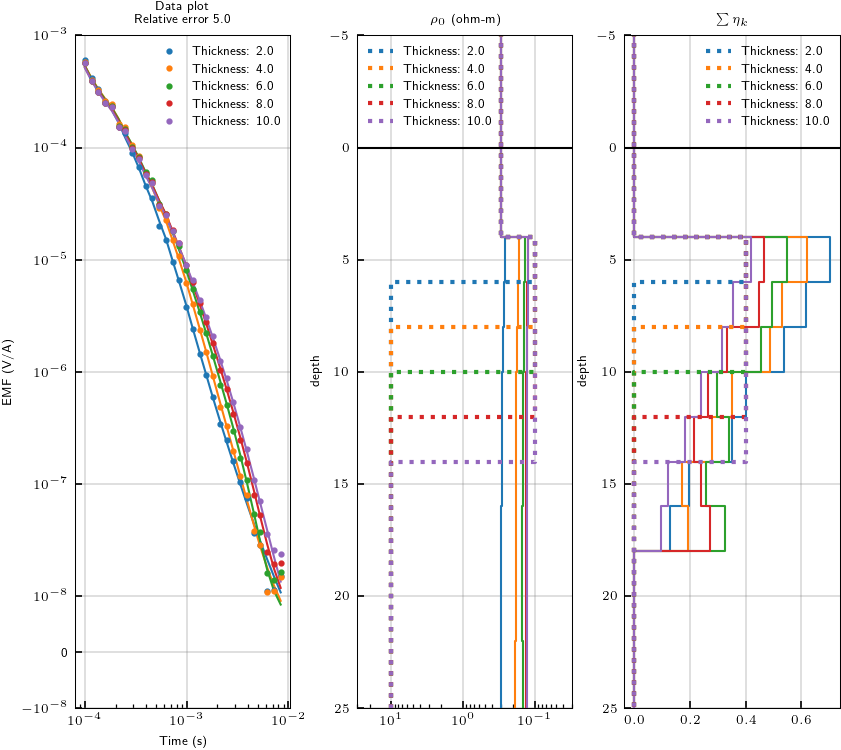

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(textwidth,5))
ax = ax.flatten()

ax[0]=plot_data(ax=ax[0])
ax[1]=plot_resistivity( ax=ax[1])
ax[2]=plot_eta_sum( ax=ax[2])
plt.savefig("../figures/21-Thickness-smallness-smoothness.png", bbox_inches="tight")

In [ ]:
mvec = models_rec_phid[0]
sim=sim_inv
model_RM = sim.Prj_RM@(sim.Prj_m@mvec + sim.m_fix)
model_R = model_RM[1:sim.nlayer]
model_M = model_RM[sim.nlayer+1:]
print(f"model_R: {model_R}")
print(f"model_M: {model_M}")
model_table = np.column_stack((model_R, model_M))
print(f"model_table shape: {model_table.shape}")
print(f"model_table: {model_table.T}")

model_R: [-1.36246424 -1.32329662 -1.28833097 -1.26304062 -1.24656028 -1.23632285
 -1.22980689 -1.22568611 -1.22303488 -1.22133591]
model_M: [0.70168527 0.6162409  0.53684124 0.40158981 0.35136931 0.19571498
 0.1300885  0.         0.         0.        ]
model_table shape: (10, 2)
model_table: [[-1.36246424 -1.32329662 -1.28833097 -1.26304062 -1.24656028 -1.23632285
  -1.22980689 -1.22568611 -1.22303488 -1.22133591]
 [ 0.70168527  0.6162409   0.53684124  0.40158981  0.35136931  0.19571498
   0.1300885   0.          0.          0.        ]]


In [ ]:
def column_stack_RM_model(mvec, sim):
    model_RM = sim.Prj_RM@(sim.Prj_m@mvec + sim.m_fix)
    model_R = model_RM[1:sim.nlayer]
    model_M = model_RM[sim.nlayer+1:]
    return np.column_stack((model_R, model_M))


def vstack_multi_RM_model(mvec_multi, sim_multi, nmodel):
    model_RM_multi = []
    for i in range(nmodel):
        mvec = sim_multi.slice_model_vector(
            mvec_multi, i)
        sim = sim_multi.simulation_list[i]
        model_RM = column_stack_RM_model(mvec, sim)
        if i == 0:
            model_RM_multi = model_RM
        else:
            model_RM_multi = np.vstack((model_RM_multi, model_RM))
    return np.array(model_RM_multi)


def plot_scatter_RM(mvec_multi, sim, nmodel, ax=None):
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(5,3))
    model_RM_multi = vstack_multi_RM_model(
        mvec_multi, sim, nmodel)
    plt.scatter(np.exp(model_RM_multi[:, 0]),
             model_RM_multi[:, 1], marker="o", color="C0", alpha=0.5)
    plt.xlim([0.03, 30])
    plt.xscale("log")
    plt.xlabel("$\rho_0$")
    plt.ylabel("$\sum\eta_k$")
    plt.title(r"Scatter plot of $\rho_0$ vs $\sum\eta_k$")
    plt.savefig("../figures/21-Thickness-scatter-Smallness-Smoothness.png", bbox_inches="tight")

multiple dataset simulation

In [ ]:
simulation_list = []
m_ref_multi_list = []
for i in range(nmodel):
    simulation_list.append(sim_inv)
    m_ref_multi_list.append(m_ref)

sim_inv_multidata = multiple_dataset_simulation(
    simulation_list=simulation_list)
sim_inv_multidata.nD_indices
m_ref_multi=np.array(m_ref_multi_list).flatten()

print(f"m_ref_multi {m_ref_multi}")

for i in range(nmodel):
    simulation_list.append(sim_obs)
sim_obs_multidata = multiple_dataset_simulation(
    simulation_list=simulation_list)
sim_obs_multidata.nD_indices

dobs_multi = np.array(dobs_cmb).flatten()

m_true_multi=np.array(m_trues).flatten()
print(f"m_true_multi {m_true_multi}")

m_ref_multi [-1.2039728 -1.2039728 -1.2039728 -1.2039728 -1.2039728 -1.2039728
 -1.2039728 -1.2039728 -1.2039728 -1.2039728  0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.        -1.2039728 -1.2039728 -1.2039728
 -1.2039728 -1.2039728 -1.2039728 -1.2039728 -1.2039728 -1.2039728
 -1.2039728  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
 -1.2039728 -1.2039728 -1.2039728 -1.2039728 -1.2039728 -1.2039728
 -1.2039728 -1.2039728 -1.2039728 -1.2039728  0.         0.
  0.         0.         0.         0.         0.         0.


Test of clipping

In [ ]:
m_test_multi_list = []
for i in range(nmodel):
    sim = sim_inv_multidata.simulation_list[i]
    m_test = np.r_[np.log((i+1)*1e2)*np.ones(sim_inv.nM_r),
              -100*(i+1)*np.ones(sim_inv.nM_m)] 
    m_test_multi_list.append(m_test)

m_test_multi = np.array(m_test_multi_list).flatten()
m_test_multi_clip = sim_inv_multidata.project_convex_set(
    m_test_multi)

for i in range(nmodel):
    sim = sim_inv_multidata.simulation_list[i]
    m_test_multi_clip_each = sim_inv_multidata.slice_model_vector(
        m_test_multi_clip, i)
    # print(m_test_multi_clip_each)
    print(sim.get_ip_model(m_test_multi_clip_each))
# sim_inv.dpred(m_ref)


{'res': array([  0.3, 100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. ,
       100. , 100. ]), 'rho_0': array([  0.3, 100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. ,
       100. , 100. ]), 'func_eta': <bound method empymod_IP_simulation.ddr of <masa_utils.empymod_IP_simulation object at 0x000002892316BD90>>, 'm_0': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_1': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_2': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_3': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_4': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_5': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_6': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_7': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_8': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_9': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}
{'res': array([  0

In [ ]:
for i in range(1):
    # sim = sim_inv_multidata.simulation_list[i]
    # print(sim.chgmin)
    # print(sim.n)
    nM_indices = sim_inv_multidata.nM_indices[i]
    # print(m_test_multi_clip[nM_indices])
    print(sim_inv_multidata.simulation_list[i].get_ip_model(m_test_multi_clip[nM_indices]))
# print(sim_inv_multidata.nM_indices)

{'res': array([  0.3, 100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. ,
       100. , 100. ]), 'rho_0': array([  0.3, 100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. ,
       100. , 100. ]), 'func_eta': <bound method empymod_IP_simulation.ddr of <masa_utils.empymod_IP_simulation object at 0x000002892316BD90>>, 'm_0': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_1': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_2': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_3': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_4': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_5': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_6': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_7': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_8': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm_9': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'm': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}


In [ ]:
sim.indices_m_list

[array([ 0, 10, 11, 13, 16, 21, 28, 35, 38]),
 array([ 1, 12, 14, 17, 22, 29, 36]),
 array([ 2, 15, 18, 23, 30, 37]),
 array([ 3, 19, 24, 31]),
 array([ 4, 20, 25, 32]),
 array([ 5, 26, 33]),
 array([ 6, 27, 34]),
 array([7]),
 array([8]),
 array([9])]

In [ ]:
sim=sim_inv
nM = sim.nM
Prj_m = sim.Prj_m
nlayer = sim.nlayer
Prj_R = np.zeros((nlayer-1, (1+ntau)*(nlayer)))
Prj_M = np.zeros((nlayer-1, (1+ntau)*(nlayer)))
for i in range(nlayer-1):
    Prj_R[i, i+1] = 1.0
    Prj_M[i, nlayer+i+1::nlayer] = 1.0

Prj_RM_cmp = np.r_[[Prj_R@Prj_m],
                   [Prj_M@Prj_m]]
print(f"Prj_RM shape: {Prj_RM_cmp.shape}")

Prj_RM shape: (2, 10, 39)


In [ ]:
def get_Prj_RM_cmp(sim):
    nM = sim.nM
    Prj_m = sim.Prj_m
    nlayer = sim.nlayer
    Prj_R = np.zeros((nlayer-1, (1+ntau)*(nlayer)))
    Prj_M = np.zeros((nlayer-1, (1+ntau)*(nlayer)))
    for i in range(nlayer-1):
        Prj_R[i, i+1] = 1.0
        Prj_M[i, nlayer+i+1::nlayer] = 1.0

    return np.r_[[Prj_R@Prj_m],
                    [Prj_M@Prj_m]]

In [ ]:
m_tem = models_rec_phid[0]
print((Prj_RM_cmp@m_tem).T)

[[-1.36246424  0.70168527]
 [-1.32329662  0.6162409 ]
 [-1.28833097  0.53684124]
 [-1.26304062  0.40158981]
 [-1.24656028  0.35136931]
 [-1.23632285  0.19571498]
 [-1.22980689  0.1300885 ]
 [-1.22568611  0.        ]
 [-1.22303488  0.        ]
 [-1.22133591  0.        ]]


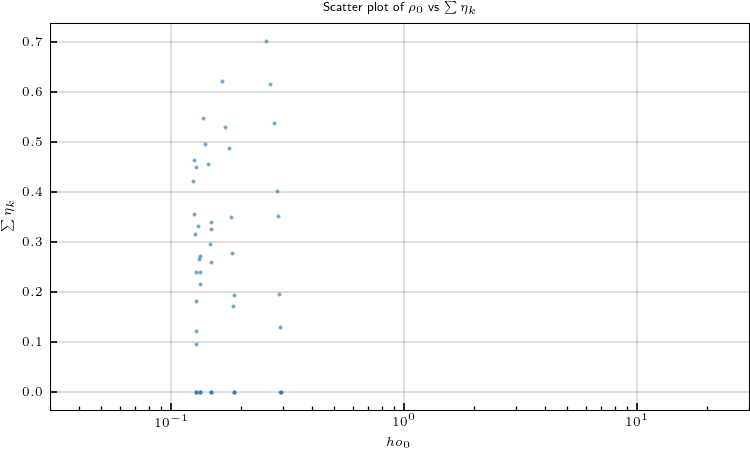

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5,3))
plot_scatter_RM(models_rec_phid_multi, sim_inv_multidata, nmodel, ax=ax)
plt.savefig("../figures/21-Thickness-scatter-Smallness-Smoothness.png", bbox_inches="tight")

# Merge dataset 

In [ ]:

for i in range(nmodel):
    sim_inv = sim_inv_multidata.simulation_list[i]
    Prj_RM_tmp = sim_inv.Prj_RM@sim_inv.Prj_m
    index = np.r_[1+np.arange(nlayer-1), nlayer+1+np.arange(nlayer-1)]    
    Prj_RM = Prj_RM_tmp[index,:]
    if i == 0:
        Prj_RM_multi = Prj_RM
    else:
        Prj_RM_multi = np.vstack((Prj_RM_multi, Prj_RM))
print(f"Prj_RM_multi shape: {Prj_RM_multi.shape}")

Prj_RM_multi shape: (100, 39)


In [ ]:
nD_multi = sim_inv_multidata.nD
nM_multi = sim_inv_multidata.nM
nlayer_multi=0
for i in range(nmodel):
    sim = sim_inv_multidata.simulation_list[i]
    nlayer_multi += sim.nlayer-1
print(nlayer_multi)

Prj_RM_cmp_multi = np.zeros((2, nlayer_multi, nM_multi))
print(f"Prj_RM_cmp_multi shape: {Prj_RM_cmp_multi.shape}")
for i in range(nmodel):
    sim = sim_inv_multidata.simulation_list[i]
    Prj_RM_cmp_multi[:, 
        i*(sim.nlayer-1):(i+1)*(sim.nlayer-1),
        i*(sim.nM) :(i+1)*(sim.nM)] = get_Prj_RM_cmp(sim)


50
Prj_RM_cmp_multi shape: (2, 50, 195)


In [ ]:
print((Prj_RM_cmp_multi@models_rec_phid_multi).T)

[[-1.36246424  0.70168527]
 [-1.32329662  0.6162409 ]
 [-1.28833097  0.53684124]
 [-1.26304062  0.40158981]
 [-1.24656028  0.35136931]
 [-1.23632285  0.19571498]
 [-1.22980689  0.1300885 ]
 [-1.22568611  0.        ]
 [-1.22303488  0.        ]
 [-1.22133591  0.        ]
 [-1.80339947  0.62143071]
 [-1.76957485  0.53061571]
 [-1.73767632  0.48703192]
 [-1.71510709  0.35023806]
 [-1.70125616  0.27789271]
 [-1.69308182  0.17245408]
 [-1.68822126  0.19337203]
 [-1.68533042  0.        ]
 [-1.6835727   0.        ]
 [-1.68250892  0.        ]
 [-1.99475153  0.54799922]
 [-1.96825029  0.49533971]
 [-1.94212396  0.45523872]
 [-1.92340773  0.29668759]
 [-1.91381572  0.3395577 ]
 [-1.90938387  0.25934136]
 [-1.90764508  0.32595748]
 [-1.90738159  0.        ]
 [-1.9077511   0.        ]
 [-1.90838096  0.        ]
 [-2.07908401  0.46472737]
 [-2.05956683  0.44899722]
 [-2.04090777  0.33148968]
 [-2.02927511  0.26573406]
 [-2.02356392  0.21512193]
 [-2.02122576  0.24056192]
 [-2.02081172  0.27192776]
 

In [ ]:
sim_inv_multidata.nM_indices

[array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35, 36, 37, 38]),
 array([39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55,
        56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72,
        73, 74, 75, 76, 77]),
 array([ 78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
         91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
        104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116]),
 array([117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
        130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
        143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155]),
 array([156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
        169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181,
        182, 183, 184, 185, 186, 187, 188, 189, 

# Inversion with GMM manually

In [ ]:
from scipy.special import logsumexp

class Optimization_GMM:  # Inherits from BaseSimulation
    def __init__(self,
                sim, # BaseSimulation,
                dobs=None,
                Wd=None, Ws=None, Wx=None, alphas=1, alphax=1,
                Ws_threshold=1e-6, eig_tol=1e-6
                ):
        self.sim = sim  # Composition: opt_tmp has a simulation
        self.dobs= dobs
        self.Wd = Wd
        self.Ws = Ws
        self.Ws_threshold = Ws_threshold
        self.Wx = Wx
        self.eig_tol = eig_tol
        self.alphas = alphas
        self.alphax = alphax

    def dpred(self, m):
        return self.sim.dpred(m)  # Calls InducedPolarization's dpred()

    def J(self, m):
        return self.sim.J(m)  # Calls InducedPolarization's J()
    
    def project_convex_set(self,m):
        return self.sim.project_convex_set(m)

    def get_Wd(self,ratio=0.10, plateau=0):
        dobs_clone = self.dobs.copy()
        noise_floor = plateau * np.ones_like(dobs_clone)
        noise_relative = dobs_clone * ratio
        std = np.sqrt(noise_floor**2 + noise_relative**2)
        self.Wd =np.diag(1 / std.flatten())
    
    def get_Ws(self, smallness):
        # if self.sim.nM is not None:
        #     self.Ws = np.eye(self.sim.nM)
        # else:
        self.smallness= smallness
        self.Ws = np.diag(smallness)

    def update_Ws(self, J):
        if self.Wd is None:
            Sensitivity = np.sqrt(np.sum(J**2, axis=0))
        else:
            Sensitivity = np.sqrt(np.sum((self.Wd@J)**2, axis=0))
        # Sensitivity = self.compute_sensitivity(self.Wd@J)
        Sensitivity /= Sensitivity.max()
        Sensitivity = np.clip(Sensitivity, self.Ws_threshold, 1)
        self.Ws = np.diag(self.smallness*Sensitivity)

    def set_beta_schedule(self, niter, beta0, coolingRate=2, coolingFactor=2.0):
        betas_list = []
        for i in range(niter):
            betas_list.append(beta0 / (coolingFactor ** (i // coolingRate)))
        self.niter, self.betas_list = niter, betas_list
        
    def set_beta_GMM_schedule(self, niter, beta0_GMM, heatingRate=2, heatingFactor=2.0):
        betas_GMM_list = []
        for i in range(niter):
            betas_GMM_list.append(beta0_GMM * (heatingFactor ** (i // heatingRate)))
        self.niter, self.betas_GMM_list = niter, betas_GMM_list

    def set_GMM_parameters(self, weights, means, covariances, gamma):
        """"""""""
        The GMM parameters are shared by all layers:
    
            means.shape        == (n_component, 2)
            covariances.shape  == (n_component, 2, 2)
            gamma.shape        == (nlayer, n_component)
    
        Parameters
        ----------
        m : ndarray, shape (nmodel,)
            Model vector.
    
        beta_GMM : float
            GMM regularization weight.
    
        means : ndarray, shape (ncomponent, nfeature)
            Mean feature vector for each GMM component.
    
        weights : ndarray, shape (ncomponent,)
            GMM component weights. Retained for API compatibility. The supplied
            responsibilities ``gamma`` are used directly in the objective.
    
        covariances : ndarray, shape (ncomponent, nfeature, nfeature)
            Covariance matrix for each GMM component.
    
        gamma : ndarray, shape (nlayer, ncomponent)
            GMM responsibility for each layer and component.
        """""""""""
        self.weights = weights
        self.means = means
        self.covariances = covariances
        self.gamma = gamma

    def loss_func_GMM(
        self,
        m,
        beta,
        beta_GMM,
        m_ref=None,
        Prj=None,
        gradient=False,
    ):
        """
        GMM regularization on two projected features for each layer.
    
        The projection has shape:
    
            Prj.shape == (n_feature, nlayer, nmodel)
    
        For this application:
    
            n_feature == 2
            z[layer, 0] == rho0[layer]
            z[layer, 1] == sum(eta_k[layer])
    
        The GMM parameters are shared by all layers:
    
            means.shape        == (n_component, 2)
            covariances.shape  == (n_component, 2, 2)
            gamma.shape        == (nlayer, n_component)
    
        Parameters
        ----------
        m : ndarray, shape (nmodel,)
            Model vector.
    
        beta_GMM : float
            GMM regularization weight.
    
        Prj : ndarray, shape (nfeature, nlayer, nmodel), optional
            Projection from model space to feature space.
    
        gradient : bool, default=False
            Return gradient and Gauss-Newton Hessian when True.
        """
        m = np.asarray(m)
    
        if m.ndim != 1:
            raise ValueError(
                f"m must have shape (nmodel,), got {m.shape}."
            )
    
        nmodel = m.size
    
        if Prj is None:
            Prj = np.eye(nmodel)[None, :, :]
    
        Prj = np.asarray(Prj)
    
        if Prj.ndim != 3:
            raise ValueError(
                "Prj must have shape (nfeature, nlayer, nmodel)."
            )
    
        nfeature, nlayer, nmodel_prj = Prj.shape
    
        if nmodel_prj != nmodel:
            raise ValueError(
                f"Prj must have {nmodel} model columns, "
                f"got {nmodel_prj}."
            )
    
        means = np.asarray(self.means)
        covariances = np.asarray(self.covariances)
        gamma = np.asarray(self.gamma)
        
        if means.ndim != 2:
            raise ValueError(
                f"means must be a 2-D array, got shape {means.shape}."
            )
        
        ncomponent, nfeature_means = means.shape

        
        expected_covariances_shape = (
            ncomponent,
            nfeature,
            nfeature,
        )
        
        if covariances.shape != expected_covariances_shape:
            raise ValueError(
                f"covariances must have shape "
                f"{expected_covariances_shape}; "
                f"got {covariances.shape}."
            )
        
        expected_gamma_shape = (nlayer, ncomponent)
        
        if gamma.shape != expected_gamma_shape:
            raise ValueError(
                f"gamma must have shape {expected_gamma_shape}; "
                f"got {gamma.shape}."
            )
        # ``weights`` is retained for compatibility. The responsibilities supplied
        # in gamma already determine each component's contribution.
        # _ = weights
    
        # Data misfit.
        dpred_m = self.dpred(m)
        rd = self.Wd @ (dpred_m - self.dobs)
        phid = 0.5 * (rd @ rd)
    
        if gradient:
            J = self.J(m)
            WdTWd = self.Wd.T @ self.Wd
    
            g_data = J.T @ self.Wd.T @ rd
            H_data = J.T @ WdTWd @ J
    
        # Change Prj from (feature, layer, model) to
        # P.shape == (layer, feature, model).
        P = Prj.transpose(1, 0, 2)
    
        # Project the model for every layer:
        #
        # z[layer] = P[layer] @ m
        #
        # z.shape == (nlayer, nfeature)
        z = P @ m
        if m_ref is not None:
            rms = self.Ws @ (m - m_ref)
            phim = 0.5 * self.alphas*np.dot(rms, rms)
            g_m = self.alphas * (self.Ws.T@self.Ws@ (m - m_ref))
            H_m = self.alphas * self.Ws.T@self.Ws
        else:
            phim = 0.0
            g_m = np.zeros(nmodel, dtype=float)
            H_m = np.zeros((nmodel, nmodel), dtype=float)
        
        phi_gmm = 0.0
    
        if gradient:
            g_gmm = np.zeros(nmodel, dtype=float)
            H_gmm = np.zeros((nmodel, nmodel), dtype=float)
    
            P_transpose = P.transpose(0, 2, 1)
    
        # Loop over GMM components, but not over layers.
        for k in range(ncomponent):
            # Difference from the shared mean of component k:
            #
            # diff.shape == (nlayer, nfeature)
            diff = z - means[k]
    
            # Solve:
            #
            # covariances[k] @ x = diff[layer]
            #
            # np.linalg.solve expects the right-hand side dimensions to be
            # (..., nfeature, nrhs), so transpose diff temporarily.
            sigma_inv_diff = np.linalg.solve(
                covariances[k],
                diff.T,
            ).T
    
            # Mahalanobis distance for every layer:
            #
            # diff[layer] @ inv(covariance[k]) @ diff[layer]
            mahalanobis = np.sum(
                diff * sigma_inv_diff,
                axis=1,
            )
    
            # Sum the regularization over layers.
            phi_gmm += 0.5 * np.sum(
                gamma[:, k] * mahalanobis,
            )
    
            if gradient:
                gamma_k = gamma[:, k]
    
                # Gradient in feature space for every layer:
                #
                # g_feature[layer] =
                #     gamma[layer, k] * inv(Sigma_k) @ diff[layer]
                #
                g_feature = gamma_k[:, None] * sigma_inv_diff
    
                # Map the feature gradient of every layer back to model space:
                #
                # P[layer].T @ g_feature[layer]
                g_gmm += np.sum(
                    P_transpose @ g_feature[..., None],
                    axis=0,
                ).ravel()
    
                # Solve Sigma_k @ X = I instead of explicitly calculating
                # inv(Sigma_k).
                sigma_inv = np.linalg.solve(
                    covariances[k],
                    np.eye(nfeature),
                )
    
                # Hessian in feature space for each layer:
                H_feature = gamma_k[:, None, None] * sigma_inv
    
                # Map the Hessian of every layer back to model space:
                #
                # P[layer].T @ H_feature[layer] @ P[layer]
                H_gmm += np.sum(
                    P_transpose @ H_feature @ P,
                    axis=0,
                )
    
        f = phid + beta*phim + beta_GMM * phi_gmm
    
        if not gradient:
            return f, phid, phim, phi_gmm, dpred_m,
    
        g = g_data + beta*g_m + beta_GMM * g_gmm
        H = H_data + beta*H_m + beta_GMM * H_gmm
    
        return f, phid, phim, phi_gmm, dpred_m, g, H  
        
    def GMM_regularization(self,mvec_init,m_ref=None,
                print_update=True,  Prj=None, s0=1.0, sfac=0.5,
        stol=1e-6, gtol=1e-3, mu=1e-4):
        self.error_prg = []
        self.data_prg = []
        self.mvec_prg = []
        self.betas = []

        mvec_old = mvec_init.copy()
        if m_ref is None:
            m_ref = mvec_init
        beta= self.betas_list[0]
        beta_GMM = self.betas_GMM_list[0]
        f_old, phid, phim, phi_gmm, _ = self.loss_func_GMM(
                mvec_old, beta, beta_GMM, m_ref,Prj=Prj, gradient=False
                )
        print(f"Initial loss: {f_old:.2e}, phid: {phid:.2e}, phim: {phim:.2e}, phi_gmm: {phi_gmm:.2e}")
        for i in range(self.niter):
            dpred_old = self.dpred(mvec_old)
            self.error_prg.append([f_old, phid, phim, phi_gmm])
            self.mvec_prg.append(mvec_old)
            self.data_prg.append(dpred_old)
            beta = self.betas_list[i]
            beta_GMM = self.betas_GMM_list[i]

            f, phid, phim, phi_gmm, dpred_m, g, H = self.loss_func_GMM(
                mvec_old,beta, beta_GMM, m_ref, Prj=Prj, gradient=True
                )

            dm = np.linalg.solve(H, g)  # Ensure dm is a 1D tensor
            # print(f"Step {i+1} - Search direction (dm): {dm}")
            g_norm = np.linalg.norm(g, ord=2)

            if g_norm < gtol:
                print(f"Inversion complete since norm of gradient is small as: {g_norm:.3e}")
                break
            s = s0
            mvec_new = self.project_convex_set(mvec_old - s * dm)
            f_new, phid, phim, phi_gmm, _ = self.loss_func_GMM(
                mvec_new,beta,  beta_GMM, m_ref,Prj=Prj,  gradient=False
                )
            directional_derivative = np.dot(g.flatten(), -dm.flatten())
            while f_new >= f_old + s * mu * directional_derivative:
                s *= sfac
                mvec_new = self.project_convex_set(mvec_old - s * dm)
                f_new, phid, phim, phi_gmm, dpred_new = self.loss_func_GMM(
                   m= mvec_new,beta=beta, m_ref=m_ref, beta_GMM=beta_GMM,Prj=Prj,
                   gradient=False
                ) #phid
                if s < stol:
                    break
            mvec_old = mvec_new
            f_old = f_new

            if print_update:
                print(f'{i+1:3}, beta:{beta:.1e}, beta_GMM:{beta_GMM:.1e}, step:{s:.1e}, g:{g_norm:.1e}, phid:{phid:.1e}, phim:{phim:.1e},, phi_gmm:{phi_gmm:.1e}, f:{f_new:.1e} ')

        self.error_prg.append([f_new, phid, phim, phi_gmm])
        self.mvec_prg.append(mvec_new)
        self.data_prg.append(dpred_new)
        return mvec_new



In [ ]:

def gaussian_logpdf(x, mean, cov):
    """
    Log probability of multivariate Gaussian.

    x           : (N, D)
    weights     : (K,)
    means       : (K, D)
    covariances : (K, D, D)
    """

    diff = x - mean

    sign, logdet = np.linalg.slogdet(cov)

    if sign <= 0:
        raise ValueError("Covariance matrix must be positive definite.")

    # Do not explicitly calculate inverse
    tmp = np.linalg.solve(cov, diff.T).T

    mahal = np.sum(diff * tmp, axis=1)

    D = x.shape[1]

    return -0.5 * (
        D * np.log(2.0 * np.pi)
        + logdet
        + mahal
    )

def gmm_e_step(x, weights, means, covariances):
    """
    Calculate responsibility gamma_ik.

    x           : (N, D)
    weights     : (K,)
    means       : (K, D)
    covariances : (K, D, D)
    """

    N = x.shape[0]
    K = len(weights)

    log_prob = np.zeros((N, K))

    for k in range(K):

        log_prob[:, k] = (
            np.log(weights[k])
            + gaussian_logpdf(
                x,
                means[k],
                covariances[k]
            )
        )

    # log p(x_i)
    log_norm = logsumexp(
        log_prob,
        axis=1,
        keepdims=True
    )

    # responsibility
    gamma = np.exp(log_prob - log_norm)
    return gamma

def gmm_m_step(x, gamma, reg_covar=1e-6):

    N, D = x.shape
    K = gamma.shape[1]

    Nk = np.sum(gamma, axis=0)

    weights = Nk / N

    means = np.zeros((K, D))
    covariances = np.zeros((K, D, D))

    for k in range(K):

        # mean
        means[k] = (
            gamma[:, k, None] * x
        ).sum(axis=0) / Nk[k]

        # covariance
        diff = x - means[k]

        covariances[k] = (
            (gamma[:, k, None] * diff).T
            @ diff
        ) / Nk[k]

        # Prevent singular covariance
        covariances[k] += (
            reg_covar * np.eye(D)
        )
    return weights, means, covariances    

In [ ]:
mvec_init_multi = models_rec_phid_multi

In [ ]:
X = (Prj_RM_cmp_multi@models_rec_phid_multi).T
print(f"X shape: {X.shape}")
print(f"X: {X}")

X shape: (50, 2)
X: [[-1.36246424  0.70168527]
 [-1.32329662  0.6162409 ]
 [-1.28833097  0.53684124]
 [-1.26304062  0.40158981]
 [-1.24656028  0.35136931]
 [-1.23632285  0.19571498]
 [-1.22980689  0.1300885 ]
 [-1.22568611  0.        ]
 [-1.22303488  0.        ]
 [-1.22133591  0.        ]
 [-1.80339947  0.62143071]
 [-1.76957485  0.53061571]
 [-1.73767632  0.48703192]
 [-1.71510709  0.35023806]
 [-1.70125616  0.27789271]
 [-1.69308182  0.17245408]
 [-1.68822126  0.19337203]
 [-1.68533042  0.        ]
 [-1.6835727   0.        ]
 [-1.68250892  0.        ]
 [-1.99475153  0.54799922]
 [-1.96825029  0.49533971]
 [-1.94212396  0.45523872]
 [-1.92340773  0.29668759]
 [-1.91381572  0.3395577 ]
 [-1.90938387  0.25934136]
 [-1.90764508  0.32595748]
 [-1.90738159  0.        ]
 [-1.9077511   0.        ]
 [-1.90838096  0.        ]
 [-2.07908401  0.46472737]
 [-2.05956683  0.44899722]
 [-2.04090777  0.33148968]
 [-2.02927511  0.26573406]
 [-2.02356392  0.21512193]
 [-2.02122576  0.24056192]
 [-2.020

In [ ]:
maxiter = 5
weights = np.array([0.3, 0.7])
K = 2
D = 2

means = np.array([
    [-2.0, 0.2],
    [ 1.0, 0.0]
])

covariances = np.array([
    [[0.3, 0.2],
     [0.2, 0.3]],

    [[0.3, 0.2],
     [0.2, 0.3]],
])
# X = Prj_RM_cmp_multi@models_rec_phid_multi
for i in range(maxiter):

    gamma = gmm_e_step(
        X,
        weights,
        means,
        covariances
    )

    weights, means, covariances = gmm_m_step(
        X,
        gamma
    )

In [ ]:
print(f"weights: {weights}")
print(f"means: {means.shape}\n{means}")  
print(f"covariances: {covariances.shape}\n{covariances}")
print(f"gamma: {gamma.shape}\n{gamma}")
covariances[1,:,:] =[[6.97652822e-02, 1.49814587e-02],
                     [1.49814587e-02, 3.99480503e-02]]

weights: [0.94000058 0.05999942]
means: (2, 2)
[[-1.83768446  0.26079741]
 [-1.2233523   0.        ]]
covariances: (2, 2, 2)
[[[7.14665223e-02 1.41173602e-02]
  [1.41173602e-02 4.04222753e-02]]

 [[4.20441820e-06 0.00000000e+00]
  [0.00000000e+00 1.00000000e-06]]]
gamma: (50, 2)
[[1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.24353915e-05 9.99987565e-01]
 [6.40276888e-06 9.99993597e-01]
 [1.00766520e-05 9.99989923e-01]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000

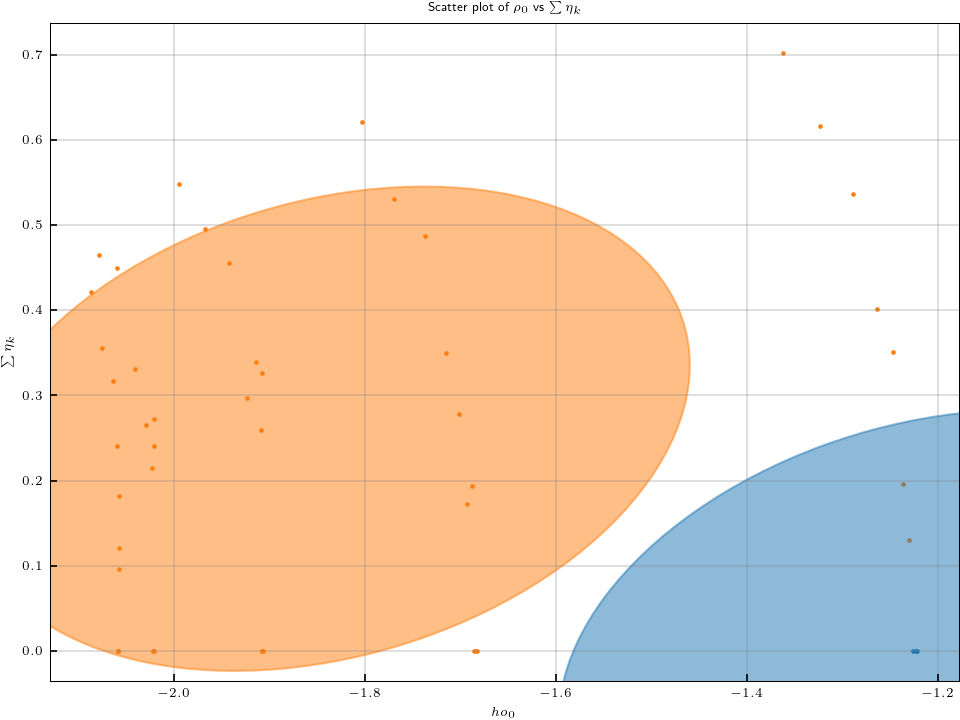

In [ ]:
Y_ = np.argmax(gamma, axis=1)

from matplotlib.patches import Ellipse
from scipy import linalg

color_iter = sns.color_palette("tab10", 2)[::-1]

fig, ax = plt.subplots()

for i, (mean, cov, color) in enumerate(
    zip(
        means,
        covariances,
        color_iter,
    )
):
    v, w = linalg.eigh(cov)
    if not np.any(Y_ == i):
        continue
    plt.scatter(X[Y_ == i, 0], X[Y_ == i, 1], 1.5, color=color)

    angle = np.arctan2(w[0][1], w[0][0])
    angle = 180.0 * angle / np.pi  # convert to degrees
    v = 2.0 * np.sqrt(2.0) * np.sqrt(v)
    ellipse = Ellipse(mean, v[0], v[1], angle=180.0 + angle, color=color)
    ellipse.set_clip_box(fig.bbox)
    ellipse.set_alpha(0.5)
    ax.add_artist(ellipse)

# ax.set_xlim([0.03, 30])
# ax.set_xscale("log")
ax.set_xlabel("$\rho_0$")
ax.set_ylabel("$\sum\eta_k$")
ax.set_title(r"Scatter plot of $\rho_0$ vs $\sum\eta_k$")
plt.savefig("../figures/21-Thickness-scatter-Smallness-Smoothness.png", bbox_inches="tight")

In [ ]:
niter = 10
stol= 1e-3
coolingFactor = 1.0
coolingRate = 2
heatingFactor = 2.0
heatingRate = 2
mu=1e-2
beta0=10
beta0_GMM= 1.0


In [ ]:
opt_multi = Optimization_GMM(
    sim=sim_inv_multidata, dobs=dobs_multi,
    alphas=1.0,Ws_threshold=Ws_threshold
    )
opt_multi.set_GMM_parameters(
    weights=weights, means=means, covariances=covariances,
    gamma=gamma
)
opt_multi.get_Wd(ratio=relative_error, plateau=noise_floor)
Wd=opt_multi.Wd
smallness = np.ones(sim_inv_multidata.nM)
opt_multi.get_Ws(smallness=smallness)
opt_multi.set_beta_schedule(
    beta0=beta0, niter=niter, 
    coolingFactor=coolingFactor, coolingRate=coolingRate
)
opt_multi.set_beta_GMM_schedule(
    beta0_GMM=beta0_GMM, niter=niter, 
    heatingFactor=heatingFactor, heatingRate=heatingRate
)
mpred = opt_multi.GMM_regularization(
mvec_init=mvec_init_multi, m_ref=m_ref_multi,
 Prj=Prj_RM_cmp_multi,stol=stol,mu=mu
)

Initial loss: 2.49e+02, phid: 8.22e+01, phim: 1.20e+01, phi_gmm: 4.70e+01
  1, beta:1.0e+01, beta_GMM:1.0e+00, step:2.5e-01, g:6.8e+02, phid:8.3e+01, phim:1.0e+01,, phi_gmm:3.8e+01, f:2.2e+02 
  2, beta:1.0e+01, beta_GMM:1.0e+00, step:1.2e-01, g:5.2e+02, phid:8.8e+01, phim:9.6e+00,, phi_gmm:3.7e+01, f:2.2e+02 
  3, beta:1.0e+01, beta_GMM:2.0e+00, step:9.8e-04, g:9.4e+02, phid:8.8e+01, phim:9.6e+00,, phi_gmm:3.6e+01, f:2.6e+02 
  4, beta:1.0e+01, beta_GMM:2.0e+00, step:9.8e-04, g:9.5e+02, phid:8.8e+01, phim:9.6e+00,, phi_gmm:3.6e+01, f:2.6e+02 
  5, beta:1.0e+01, beta_GMM:4.0e+00, step:9.8e-04, g:1.0e+03, phid:8.8e+01, phim:9.6e+00,, phi_gmm:3.6e+01, f:3.3e+02 
  6, beta:1.0e+01, beta_GMM:4.0e+00, step:6.2e-02, g:1.0e+03, phid:9.5e+01, phim:9.5e+00,, phi_gmm:3.5e+01, f:3.3e+02 


In [ ]:
X = (Prj_RM_cmp_multi@mpred).T
Y_ = np.argmax(gamma, axis=1)

In [ ]:
def plot_gmm_scatter(X, Y_, ax=None):
    if ax is None:
        fig, ax = plt.subplots()

    color_iter = sns.color_palette("tab10", 2)[::-1]

    for i, (mean, cov, color) in enumerate(
        zip(
            means,
            covariances,
            color_iter,
            )
        ):
        v, w = linalg.eigh(cov)
        if not np.any(Y_ == i):
            continue
        ax.scatter(np.exp(X[Y_ == i, 0]),
                    X[Y_ == i, 1], 1.5, color=color)

        angle = np.arctan2(w[0][1], w[0][0])
        angle = 180.0 * angle / np.pi  # convert to degrees
        v = 2.0 * np.sqrt(2.0) * np.sqrt(v)
        ellipse = Ellipse(mean, v[0], v[1], angle=180.0 + angle, color=color)
        ellipse.set_clip_box(fig.bbox)
        ellipse.set_alpha(0.5)
        ax.add_artist(ellipse)

    ax.set_xlim([0.03, 30])
    ax.set_xscale("log")
    ax.set_xlabel("$\rho_0$")
    ax.set_ylabel("$\sum\eta_k$")
    ax.set_title(r"Scatter plot of $\rho_0$ vs $\sum\eta_k$")


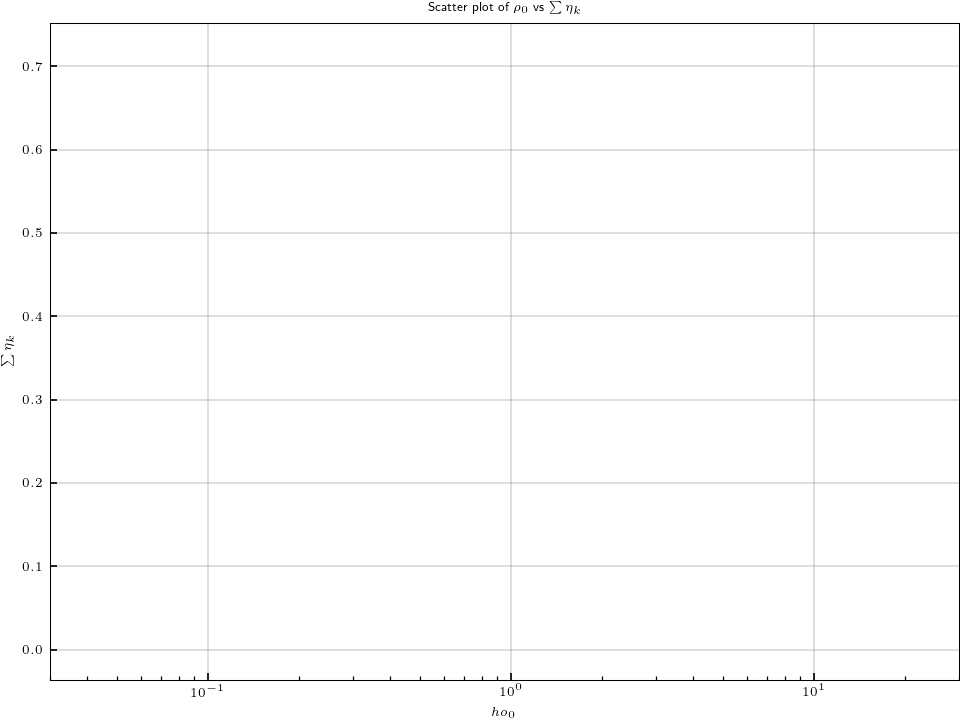

In [ ]:

plot_gmm_scatter(X, Y_)
plt.savefig("../figures/21-Thickness-scatter-Smallness-Smoothness-GMM.png", bbox_inches="tight")

In [ ]:
models_rec_GMM = []
dpreds_GMM = []
for i in range(nmodel):
    model_rec_GMM = sim_inv_multidata.slice_model_vector(mpred,i)
    models_rec_GMM.append(model_rec_GMM)
    sim = sim_inv_multidata.simulation_list[i]
    dpred = sim.dpred(model_rec_GMM)
    dpreds_GMM.append(dpred)



IndexError: index 39 is out of bounds for axis 0 with size 39

In [ ]:
def plot_data_GMM( ax=None):
    if ax is None: 
        fig, ax = plt.subplots(1, 1, figsize=(5,3))
    for i in range(nmodel):
        color = f"C{i}"
        label = None
        ax=PL_decay.semiply(windows_cen-rmp_time, dpreds_GMM[i], ax=ax
                            ,color=color,linestyle="-",label=label
                            )
    for i in range(nmodel):
        color = f"C{i}"
        label = f"Thickness: {thickness_list[i]:.1f}"
        dobs= dobs_cmb[i]
        ax=PL_decay.semiply(
            windows_cen-rmp_time, dobs, ax=ax, marker="o",markersize=2.0,
            color=color,linestyle="", label=label
            )
    ax = PL_decay.pl_axes(ax)
    ax.legend()
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("EMF (V/A)")
    ax.set_title(f""" Data plot
Relative error {relative_error*100:.1f} %, noise floor {data_noise_floor:.1e} V/A""")
    return ax

In [ ]:
def plot_resistivity_GMM(ax):
    for i in range(nmodel):
        color = f"C{i}"
        label = None
        m_tem = models_rec_GMM[i]
        model= sim.get_ip_model(m_tem)
        ax = sim.plot_model(model["res"], 
            color=color, linestyle="-", label=label,ax=ax)
    for i in range(nmodel):
        color = f"C{i}"
        label = f"Thickness: {thickness_list[i]:.1f}"
        m_true = m_trues[i]
        model= sim.get_ip_model(m_true)
        ax = sim.plot_model(model["res"], 
            color=color, linestyle=":",label=label,linewidth=2, ax=ax)

    ax.set_xlim([30,0.03])
    ax.legend()
    ax.axhline(empymod_model_sim["src"][4], color="k", linestyle="-", label="Src+Rec")
    ax.set_ylim([25, -5.0])
    ax.set_ylabel('depth')
    ax.set_xscale("log")
    ax.set_title(r"$\rho_0$ (ohm-m)")
    return ax

In [ ]:
def plot_eta_sum_GMM(ax):
    for i in range(nmodel):
        color = f"C{i}"
        label = None
        m_tem = models_rec_GMM[i]
        model= sim_inv.get_ip_model(m_tem)
        ax = sim_inv.plot_model(model["m"], 
            color=color, linestyle="-", label=label,ax=ax)
    for i in range(nmodel):
        color = f"C{i}"
        label = f"Thickness: {thickness_list[i]:.1f}"
        m_true = m_trues[i]
        model= sim_obs.get_ip_model(m_true)
        ax = sim_obs.plot_model(model["m"], 
            color=color, linestyle=":",label=label,linewidth=2, ax=ax)
    ax.legend()
    ax.axhline(empymod_model_sim["src"][4], color="k", linestyle="-", label="Src+Rec")
    ax.set_ylim([25, -5.0])
    ax.set_ylabel('depth')
    ax.set_title(r"$\sum\eta_k$")
    return ax

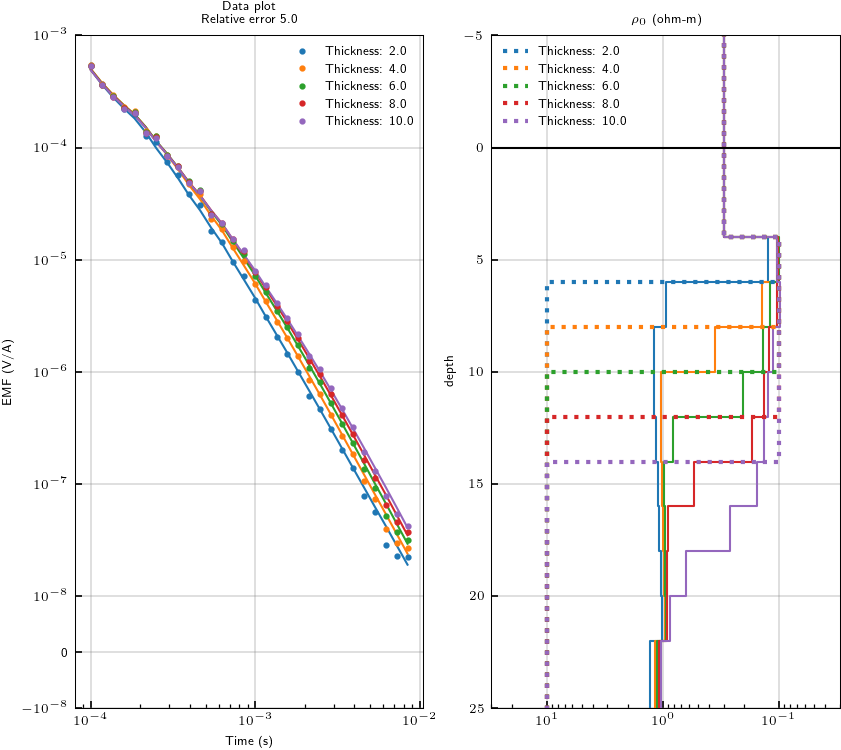

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(textwidth,5))
ax = ax.flatten()

ax[0]=plot_data(ax=ax[0])
ax[1]=plot_resistivity( ax=ax[1])
ax[2]=plot_eta_sum( ax=ax[2])

plt.savefig("../figures/21-thickness-noIP-GMM1.png", bbox_inches="tight")

# GMM 2nd

In [ ]:
maxiter = 10
covariances_old = covariances.copy()
X = mpred.reshape(-1, 1)
for i in range(maxiter):

    gamma = gmm_e_step(
        X,
        weights,
        means,
        covariances
    )

    weights, means, covariances = gmm_m_step(
        X,
        gamma
    )
mvec_init_multi = mpred
# covarience is not updated 
covariances = covariances_old

In [ ]:
print(f"weights: {weights}")
print(f"means: {means.flatten()}")  
print(f"covariances: {covariances.flatten()}")
print(f"gamma: {gamma}")


weights: [0.40049676 0.59950324]
means: [-1.99194275 -0.01702526]
covariances: [0.09508352 0.86206794]
gamma: [[1.00000000e+00 9.44649926e-32]
 [1.37734256e-08 9.99999986e-01]
 [3.14726967e-10 1.00000000e+00]
 [3.83298197e-10 1.00000000e+00]
 [5.90555409e-10 9.99999999e-01]
 [9.50526706e-10 9.99999999e-01]
 [1.53252807e-09 9.99999998e-01]
 [2.44260359e-09 9.99999998e-01]
 [3.80739443e-09 9.99999996e-01]
 [1.23850065e-10 1.00000000e+00]
 [1.00000000e+00 3.95933220e-37]
 [1.00000000e+00 5.96224390e-28]
 [9.99996660e-01 3.33962609e-06]
 [2.94550267e-09 9.99999997e-01]
 [2.80786306e-09 9.99999997e-01]
 [3.73886257e-09 9.99999996e-01]
 [5.21284712e-09 9.99999995e-01]
 [7.26092254e-09 9.99999993e-01]
 [9.89509244e-09 9.99999990e-01]
 [4.37835494e-10 1.00000000e+00]
 [1.00000000e+00 3.94369294e-38]
 [1.00000000e+00 1.04660190e-32]
 [1.00000000e+00 1.26270753e-28]
 [1.00000000e+00 3.76896261e-18]
 [3.61966481e-07 9.99999638e-01]
 [9.16249904e-09 9.99999991e-01]
 [1.01878630e-08 9.99999990e-01]

In [ ]:
niter = 6
stol=1e-3
coolingFactor = 0.5
coolingRate = 2
mu=1e-2
beta0= 0.50
beta0_ratio = 1


In [ ]:
opt_multi = Optimization_GMM(
    sim=sim_multidata, dobs=dobs_multi,
    alphas=1.0,Ws_threshold=Ws_threshold
    )
opt_multi.get_Wd(ratio=relative_error, plateau=noise_floor)
Wd=opt_multi.Wd
smallness = np.ones(sim_multidata.nM)
opt_multi.get_Ws(smallness=smallness)
print(beta0)
mpred = opt_multi.GMM_regularization(
mvec_init=mvec_init_multi,niter=niter,beta0=beta0,
weights=weights, means=means, covariances=covariances,gamma=gamma,
stol=stol,mu=mu,coolingRate=coolingRate, coolingFactor=coolingFactor
)


0.5
  1, beta:5.0e-01, step:1.0e+00, g:2.1e+01, phid:8.4e+01, phim:1.2e+01, f:9.0e+01 
  2, beta:5.0e-01, step:1.0e+00, g:9.6e+01, phid:8.0e+01, phim:1.2e+01, f:8.6e+01 
  3, beta:1.0e+00, step:9.8e-04, g:1.6e+01, phid:8.0e+01, phim:1.2e+01, f:9.2e+01 
  4, beta:1.0e+00, step:1.0e+00, g:1.6e+01, phid:8.2e+01, phim:8.4e+00, f:9.1e+01 
  5, beta:2.0e+00, step:9.8e-04, g:1.5e+01, phid:8.2e+01, phim:8.4e+00, f:9.9e+01 
  6, beta:2.0e+00, step:1.0e+00, g:1.5e+01, phid:8.6e+01, phim:6.0e+00, f:9.8e+01 


res_rec [0.11813812 1.31090895 1.41205505 1.4005868  1.35987716 1.3110679
 1.26244714 1.2177152  1.17827585 1.61017525 0.10353892 0.16995239
 0.18810199 1.39172012 1.35070328 1.30107125 1.25198988 1.20727513
 1.16834064 1.54182978 0.09866376 0.12386289 0.147225   0.15720671
 1.17533181 1.1627128  1.14172982 1.11979194 1.09930287 1.38921569
 0.10282697 0.1005335  0.12424387 0.13974524 0.14603506 0.76116421
 1.07935062 1.07172523 1.06221457 1.30666649 0.10552751 0.09299563
 0.11405163 0.13390415 0.14385553 0.14794963 0.14886143 1.08231817
 1.07582708 1.32072555]


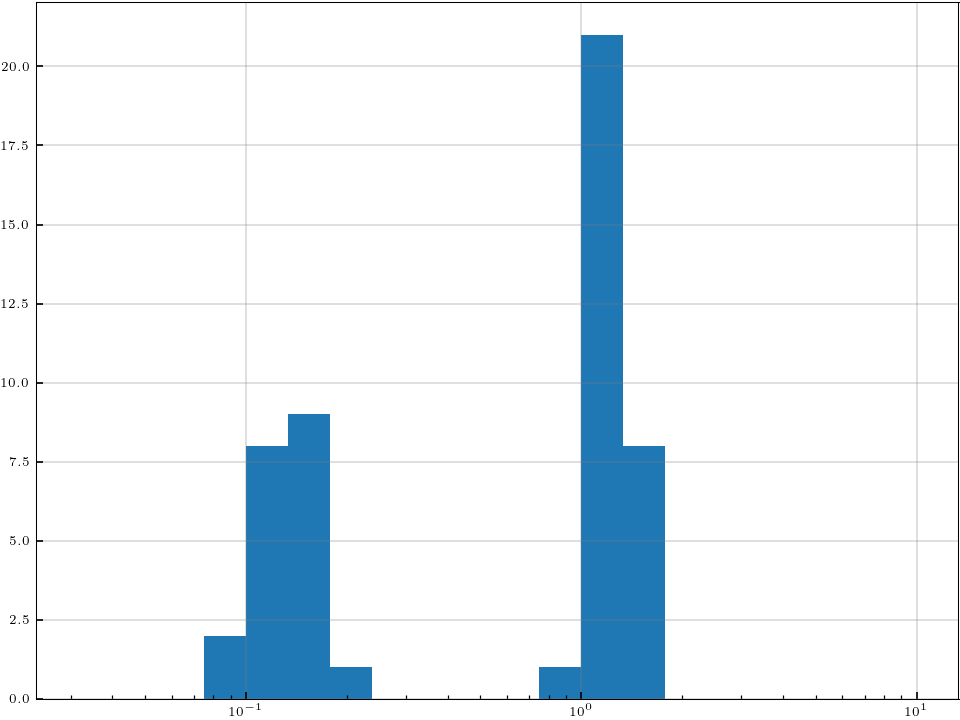

In [ ]:

res_rec = np.exp(mpred)
print(f"res_rec {res_rec}")
bins = np.logspace(-1.5,1.0,num=21)
plt.hist(res_rec, bins=bins)
plt.xscale("log")
plt.savefig("../figures/21-thickness-noIP-hist-GMM2.png", bbox_inches="tight")

In [ ]:
models_rec_GMM = []
dpreds_GMM = []
for i in range(nmodel):
    model_rec_GMM = sim_multidata.slice_model_vector(mpred,i)
    models_rec_GMM.append(model_rec_GMM)
    sim = sim_multidata.simulation_list[i]
    dpred = sim.dpred(model_rec_GMM)
    dpreds_GMM.append(dpred)



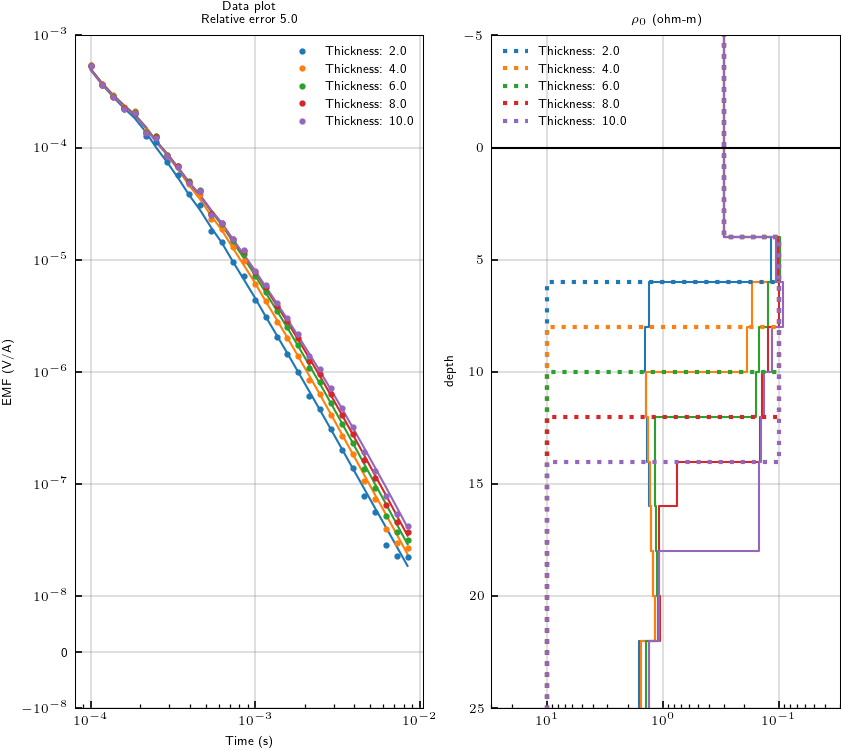

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(textwidth,5))
ax = ax.flatten()

ax[0]=plot_data_GMM(ax=ax[0])
ax[1]=plot_resistivity_GMM(ax=ax[1])

plt.savefig("../figures/21-thickness-noIP-GMM2.png", bbox_inches="tight")

# GMM 3rd

In [ ]:
maxiter = 10

X = mpred.reshape(-1, 1)
for i in range(maxiter):

    gamma = gmm_e_step(
        X,
        weights,
        means,
        covariances
    )

    weights, means, covariances = gmm_m_step(
        X,
        gamma
    )
mvec_init_multi = mpred
# do not updte covariances
covariances = covariances_old

In [ ]:
print(f"weights: {weights}")
print(f"means: {means.flatten()}")  
print(f"covariances: {covariances.flatten()}")
print(f"gamma: {gamma}")


weights: [0.4 0.6]
means: [-2.05634673  0.20365567]
covariances: [0.09508352 0.86206794]
gamma: [[1.00000000e+00 5.74807826e-61]
 [3.81771496e-32 1.00000000e+00]
 [5.39182059e-34 1.00000000e+00]
 [8.54774487e-34 1.00000000e+00]
 [4.58774609e-33 1.00000000e+00]
 [3.79085859e-32 1.00000000e+00]
 [3.48233335e-31 1.00000000e+00]
 [2.98871115e-30 1.00000000e+00]
 [2.18583917e-29 1.00000000e+00]
 [4.04711101e-37 1.00000000e+00]
 [1.00000000e+00 9.01294932e-68]
 [1.00000000e+00 3.64177002e-43]
 [1.00000000e+00 1.89319590e-38]
 [1.22514496e-33 1.00000000e+00]
 [6.76655654e-33 1.00000000e+00]
 [5.92359001e-32 1.00000000e+00]
 [5.70035283e-31 1.00000000e+00]
 [5.01606111e-30 1.00000000e+00]
 [3.66208793e-29 1.00000000e+00]
 [4.15961511e-36 1.00000000e+00]
 [1.00000000e+00 2.63410200e-70]
 [1.00000000e+00 1.43069651e-58]
 [1.00000000e+00 5.03624924e-50]
 [1.00000000e+00 7.30617266e-47]
 [2.54536751e-29 1.00000000e+00]
 [4.91887239e-29 1.00000000e+00]
 [1.50444060e-28 1.00000000e+00]
 [4.99454357e

In [ ]:
niter = 6
stol=1e-3
coolingFactor = 0.5
coolingRate = 2
mu=1e-2
beta0= 0.50
beta0_ratio = 1


In [ ]:
opt_multi = Optimization_GMM(
    sim=sim_multidata, dobs=dobs_multi,
    alphas=1.0,Ws_threshold=Ws_threshold
    )
opt_multi.get_Wd(ratio=relative_error, plateau=noise_floor)
Wd=opt_multi.Wd
smallness = np.ones(sim_multidata.nM)
opt_multi.get_Ws(smallness=smallness)
print(beta0)
mpred = opt_multi.GMM_regularization(
mvec_init=mvec_init_multi,niter=niter,beta0=beta0,
weights=weights, means=means, covariances=covariances,gamma=gamma,
stol=stol,mu=mu,coolingRate=coolingRate, coolingFactor=coolingFactor
)


0.5


  1, beta:5.0e-01, step:1.0e+00, g:1.3e+01, phid:7.9e+01, phim:9.9e+00, f:8.4e+01 
  2, beta:5.0e-01, step:1.0e+00, g:2.3e+01, phid:7.9e+01, phim:9.0e+00, f:8.4e+01 
  3, beta:1.0e+00, step:9.8e-04, g:6.3e+00, phid:7.9e+01, phim:9.0e+00, f:8.8e+01 
  4, beta:1.0e+00, step:1.0e+00, g:6.3e+00, phid:8.1e+01, phim:6.1e+00, f:8.7e+01 
  5, beta:2.0e+00, step:9.8e-04, g:1.2e+01, phid:8.1e+01, phim:6.1e+00, f:9.3e+01 
  6, beta:2.0e+00, step:1.0e+00, g:1.2e+01, phid:8.4e+01, phim:4.0e+00, f:9.2e+01 


res_rec [0.1156109  1.51923278 1.59451276 1.58274133 1.54477516 1.50059894
 1.45789471 1.4195055  1.38619829 1.76796489 0.10455399 0.16547233
 0.17935895 1.66286522 1.60727667 1.54782707 1.49290195 1.44523059
 1.40512966 1.79981815 0.099187   0.12369849 0.14332176 0.15094548
 1.43387191 1.41211917 1.38658184 1.36207982 1.34025192 1.64285533
 0.10271287 0.102051   0.12152857 0.13432816 0.1390279  1.33144013
 1.32482528 1.31464538 1.30377363 1.55542782 0.10492899 0.0945426
 0.11406849 0.13151255 0.13986012 0.14272366 0.14266056 1.34658159
 1.3308946  1.60254116]


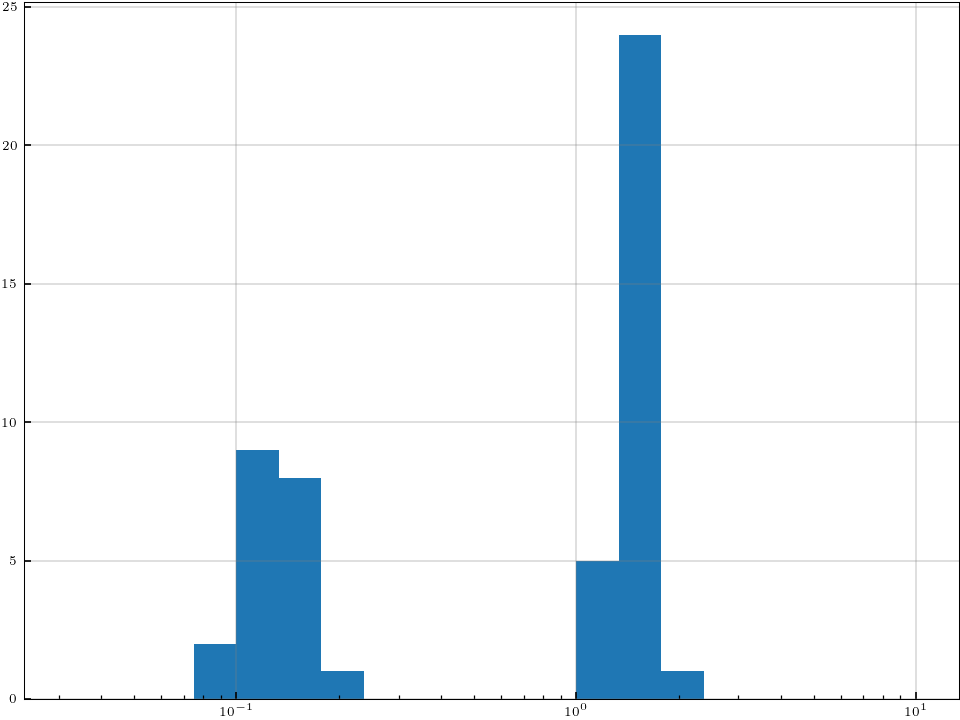

In [ ]:

res_rec = np.exp(mpred)
print(f"res_rec {res_rec}")
bins = np.logspace(-1.5,1.0,num=21)
plt.hist(res_rec, bins=bins)
plt.xscale("log")
plt.savefig("../figures/21-thickness-noIP-hist-GMM3.png", bbox_inches="tight")

In [ ]:
models_rec_GMM = []
dpreds_GMM = []
for i in range(nmodel):
    model_rec_GMM = sim_multidata.slice_model_vector(mpred,i)
    models_rec_GMM.append(model_rec_GMM)
    sim = sim_multidata.simulation_list[i]
    dpred = sim.dpred(model_rec_GMM)
    dpreds_GMM.append(dpred)



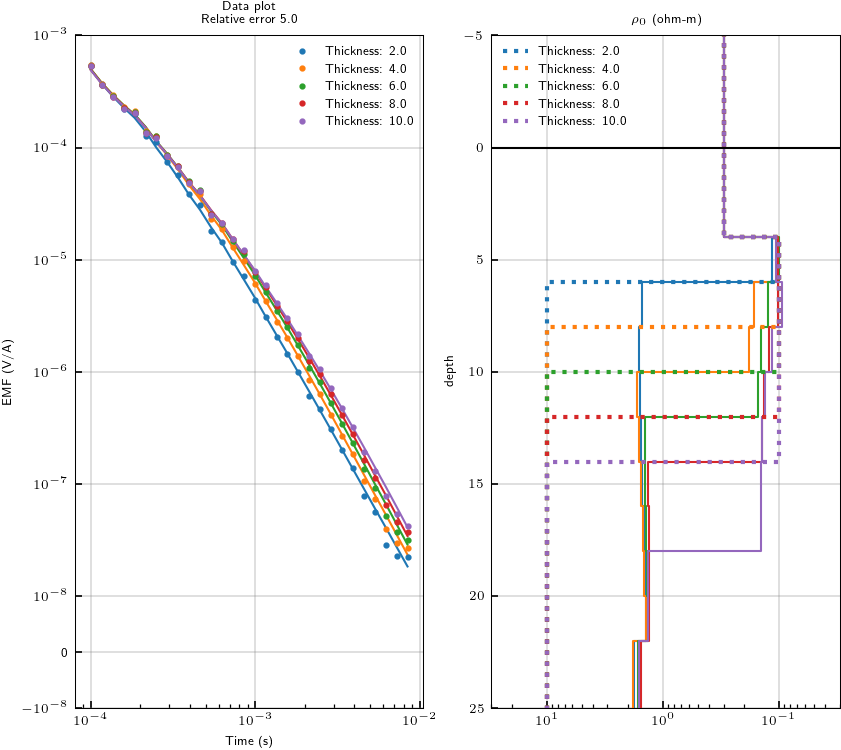

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(textwidth,5))
ax = ax.flatten()

ax[0]=plot_data_GMM(ax=ax[0])
ax[1]=plot_resistivity_GMM(ax=ax[1])

plt.savefig("../figures/21-thickness-noIP-GMM3.png", bbox_inches="tight")